<a href="https://colab.research.google.com/github/AhmadSelao180874/LSTM_Perbandingan-Model/blob/main/ProjectBIMA26_Split3Arah_Terisolasi_MultiSeed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model Terintegrasi v7.1 — Custom CNN vs MobileNetV2 vs VGG16 vs YOLOv8-cls
## Klasifikasi biner sampah plastik pesisir — Sentinel-2A true-color (patch 32×32 px, 10 m)
### Split 3-arah terisolasi (±68:12:20) · multi-seed · Bootstrap 95% CI · McNemar (koreksi Holm)

**Cara menjalankan (penting):**
1. `Runtime → Restart session` (atau *Disconnect and delete runtime*), lalu pilih GPU (T4).
2. `Runtime → Run all`. Jangan menjalankan sel secara acak atau berulang di sesi yang sama.
3. Setelah selesai: `File → Download → Download .ipynb` (output ikut tersimpan) dan kirimkan hasilnya.

**Skema partisi.** Dari seluruh patch yang lolos pembersihan data: 20% dikeluarkan lebih dulu sebagai **test terisolasi**
(stratified, `split_seed=42`, dikunci sampai prediksi akhir); dari 80% sisanya, 15% diambil sebagai **validasi-internal**
(khusus EarlyStopping / ReduceLROnPlateau / pemilihan `best.pt` YOLO); sisanya adalah **train**. Proporsinya ≈ 68 : 12 : 20.
Ukuran pasti tiap bagian bergantung pada jumlah patch yang lolos dedup (ID + isi piksel) dan **dicetak oleh sel "Split"**
serta ditulis di `run_manifest.json` — gunakan angka dari log itu di naskah, bukan angka dari versi lama
(pada run v7 di Colab: 385 baris → 377 bersih, karena 8 baris dibuang akibat `Patch_ID` ganda berlabel bertentangan → train / val / test = 255 / 46 / 76; Acuan_3 tidak membuang apa pun sehingga n_test = 77).

---

## Amandemen protokol v7.1 (dibuat SETELAH run v7 seed 42 — harus dilaporkan terbuka)

Run v7 (seed 42) menunjukkan dua masalah yang terlihat pada kurva **validasi-internal**:

| # | Gejala pada run v7 (seed 42) | Mekanisme | Amandemen di v7.1 |
|---|---|---|---|
| A | **Custom CNN tidak stabil di ketiga seed** (akurasi test 44,7 / 72,4 / 72,4%; seed 42 memprediksi semua patch "plastik", κ = 0). EarlyStopping (patience 20) berhenti di epoch 21 / 21 / 30, artinya bobot yang dipulihkan berasal dari epoch **1 / 1 / 10**. Pada seed 42 val-accuracy datar 0,4565 selama 20 epoch (train 0,63 → 0,82) dan val-loss naik ke 3,0 (epoch 7) lalu turun ke 1,2 (epoch 21), jadi model masih "pulih" ketika dihentikan | Epoch awal kebetulan punya val-loss terendah lalu terpilih. Penyebab val-accuracy yang datar belum jelas (hipotesis: statistik BatchNorm yang tertinggal, atau selisih augmentasi train vs validasi). *Belum diuji; lihat diagnostik di bawah.* | `es_start_from_epoch = 15` untuk **semua** model Keras: EarlyStopping tidak memantau dan tidak menyimpan bobot sebelum epoch 16 |
| B | **VGG16 tidak stabil** saat fine-tuning penuh (lr 1e-4): pada seed 42 val-accuracy meloncat 0,45 ↔ 0,96 dan val-loss melonjak hingga ≈ 6,3; checkpoint terpilih (epoch ke-3 fine-tune, val-acc 0,957) adalah satu epoch yang "kebetulan baik" di tengah lintasan yang kacau | Seluruh 14,7 jt parameter dibuka dengan lr sebesar lr fase-1 | `vgg_finetune_lr`: 1e-4 → **1e-5** (setara lr fine-tune MobileNetV2) |

**Diagnostik baru di v7.1 (tanpa menyentuh test):** untuk tiap model Keras dicetak akurasi pada **data train tanpa augmentasi (mode inferensi)** berdampingan dengan akurasi validasi-internal.
Train tinggi + validasi rendah → celah generalisasi (model benar-benar tidak menggeneralisasi). Keduanya rendah → masalah mode-inferensi (BatchNorm / selisih augmentasi), bukan masalah data.
Sel dedup juga mencetak baris yang dibuang (Patch_ID ganda berlabel bertentangan) agar bisa dicek di GIS.

**Catatan kejujuran ilmiah:**
- kurva *validasi-internal*, tetapi hasil *test* run v7 sudah dilihat sebelum amandemen dibuat. Jadi
  amandemen ini **tidak sepenuhnya buta terhadap test**; sebut apa adanya.
- Laporkan **kedua** protokol: protokol awal (v7, `es_start_from_epoch=0`, `vgg_finetune_lr=1e-4`) dan protokol amandemen (v7.1).
  Seed utama tetap seed pertama (42) — tidak boleh diganti setelah melihat hasil.
- Set uji hanya 76–77 patch: satu patch ≈ 1,3 poin; selisih beberapa patch antar model tidak bermakna secara statistik.
- Bila Custom CNN **tetap** kolaps di v7.1, laporkan apa adanya (sel ringkasan mencetak diagnostik degenerasi per seed dan model);
  jangan menyetel lagi sampai "berhasil" memakai hasil test.

Nilai awal v7 dipulihkan dengan `CONFIG["es_start_from_epoch"] = 0` dan `CONFIG["vgg_finetune_lr"] = 1e-4` (folder keluaran v7.1 terpisah
dari v7 sehingga hasil lama tidak tertimpa).

---

**Perubahan terhadap Acuan_3 (semuanya untuk menutup celah):**

| # | Masalah di Acuan_3 | Perbaikan di v7 / v7.1 |
|---|---|---|
| 1 | `prepare_yolo_folder_structure_weighted` dipanggil tetapi tidak pernah didefinisikan (`NameError`); folder `test/` YOLO tidak dibuat | Fungsi didefinisikan; membuat `train/`, `val/`, `test/`; folder dihapus-bangun ulang tiap run (tidak ada sisa file lama) |
| 2 | Oversampling (`ceil`) + `class_weight` menumpuk (kelas plastik jadi mayoritas di train YOLO, yang tidak memakai `class_weight`) | Satu mekanisme saja, dipilih lewat `CONFIG["balance_mode"]` (default `class_weight`) |
| 3 | Hash cache hanya memeriksa nama file test | Fingerprint mencakup train+val+test, seed, versi kode, dan semua hyper-parameter |
| 4 | Tidak ada pemeriksaan patch kembar / korelasi spasial | Dedup ID + konten piksel; diagnostik jarak tetangga terdekat test→train (bila ada kolom koordinat) |
| 5 | Satu seed saja | `train_seeds` (default 3); split tetap, hanya stokastisitas training yang berubah; seed utama ditetapkan di muka = seed pertama |
| 6 | Fine-tuning MobileNetV2: `layer.trainable=True` pada lapisan dalam base yang pembungkusnya masih `trainable=False` bisa tidak berefek | `base.trainable=True` dibuka dulu; jumlah parameter *trainable* dicetak dan notebook **berhenti dengan error** bila fine-tuning ternyata tidak aktif |
| 7 | VGG16 memakai `num_unfreeze_layers=0` (kebetulan berarti "semua lapisan") | Dibuat eksplisit: seluruh lapisan dibuka |
| 8 | Hanya satu angka per model | Tabel per-seed + rerata ± SD; bootstrap & McNemar pada seed utama; McNemar dengan koreksi Holm |
| 9 | Kurva & confusion matrix terpisah-pisah | Satu figur kurva 4 model; satu figur confusion matrix 4 model; analisis patch yang salah di semua model |
| 10 | (opsional) tidak ada kuantifikasi dampak kebocoran | `run_leaky_arm=True` melatih ulang dengan *test dipakai sebagai monitor* pada training set yang sama, untuk mengukur bias optimistik protokol lama |
| 11 | (v7.1) EarlyStopping dapat memulihkan bobot epoch 1 | `es_start_from_epoch`; log mencetak epoch asal bobot akhir; diagnostik degenerasi per seed dan model |

**Yang sengaja TIDAK diubah** agar perlakuan sama dengan run sebelumnya: arsitektur Custom CNN, augmentasi, input 0–1 (`rescale=1/255`)
untuk semua model, hyper-parameter YOLO, patience Custom CNN = 20, resize 32→96 untuk MobileNetV2.
Catatan: `rescale=1/255` bukan pra-pemrosesan bawaan ImageNet untuk MobileNetV2/VGG16; ini dipertahankan agar konsisten dan
sebaiknya disebut sebagai keterbatasan di naskah.

## 1. Setup & Konfigurasi

In [1]:
# ==========================================
# IMPORTS & LOGGER
# ==========================================
import os
import re
import sys
import gc
import json
import math
import time
import shutil
import random
import hashlib
import logging
import platform
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:  # saat dijalankan di luar Jupyter/Colab
    def display(obj):
        print(obj)

try:
    import tensorflow as tf
    from tensorflow.keras import layers, models, regularizers
    from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, Callback
    from tensorflow.keras.preprocessing.image import ImageDataGenerator
    from tensorflow.keras.applications import MobileNetV2, VGG16
    from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
    from tensorflow.keras.models import Model
    from tensorflow.keras.optimizers import Adam
except ImportError as e:
    raise ImportError(
        f"TensorFlow/Keras tidak ditemukan atau gagal diimpor: {e}. "
        f"Install dengan: pip install tensorflow"
    ) from e

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, cohen_kappa_score,
                             accuracy_score, f1_score)
from sklearn.utils.class_weight import compute_class_weight

CODE_VERSION = "v7.1-isolated-3way-multiseed-esstart"


def setup_logging():
    """Logger konsisten untuk seluruh pipeline -- tampil di console + tersimpan ke file."""
    lg = logging.getLogger("plastik_pipeline")
    lg.setLevel(logging.INFO)
    lg.handlers.clear()
    lg.propagate = False
    fmt = logging.Formatter("[%(asctime)s] %(levelname)s: %(message)s", datefmt="%H:%M:%S")

    sh = logging.StreamHandler(sys.stdout)
    sh.setFormatter(fmt)
    lg.addHandler(sh)

    try:
        fh = logging.FileHandler("pipeline_log.txt", mode="a", encoding="utf-8")
        fh.setFormatter(fmt)
        lg.addHandler(fh)
    except OSError as e:
        print(f"PERINGATAN: gagal membuat file log: {e}. Lanjut dengan console logging saja.")
    return lg


logger = setup_logging()
logger.info(f"Logger siap. Notebook {CODE_VERSION}: split 3-arah terisolasi + multi-seed + amandemen protokol v7.1.")

[12:10:41] INFO: Logger siap. Notebook v7.1-isolated-3way-multiseed-esstart: split 3-arah terisolasi + multi-seed + amandemen protokol v7.1.


In [2]:
# ==========================================
# MOUNT GOOGLE DRIVE (khusus Colab) -- aman dijalankan berulang
# ==========================================
try:
    from google.colab import drive
    drive.mount('/content/drive')
    logger.info("Google Drive berhasil di-mount.")
except ImportError:
    logger.warning(
        "Modul 'google.colab' tidak ditemukan -- sepertinya bukan berjalan di Colab. "
        "Pastikan path CONFIG di bawah disesuaikan dengan environment lokal Anda."
    )
except Exception as e:
    logger.error(f"Gagal mount Google Drive: {e}")
    raise

Mounted at /content/drive
[12:11:37] INFO: Google Drive berhasil di-mount.


In [3]:
# ==========================================
# CEK GPU & VERSI LIBRARY
# ==========================================
gpu_devices = tf.config.list_physical_devices('GPU')
if gpu_devices:
    logger.info(f"GPU terdeteksi: {gpu_devices}")
else:
    logger.warning(
        "TIDAK ADA GPU terdeteksi (GPU Available: []). Training akan SANGAT LAMBAT. "
        "Di Colab: Runtime > Change runtime type > pilih GPU (T4), lalu restart runtime."
    )

import sklearn
logger.info(
    f"Versi: python={platform.python_version()}, tensorflow={tf.__version__}, "
    f"numpy={np.__version__}, pandas={pd.__version__}, sklearn={sklearn.__version__}"
)

[12:11:39] INFO: GPU terdeteksi: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
[12:11:39] INFO: Versi: python=3.13.15, tensorflow=2.21.0, numpy=2.1.3, pandas=2.2.3, sklearn=1.6.1


### Konfigurasi global

Semua saklar yang menentukan hasil ada di sel ini. Tiga yang paling penting: `balance_mode` (penyeimbang kelas), `train_seeds` (jumlah seed), dan `dedup_by_*` / `spatial_cols` (pembersihan & diagnostik spasial). Folder keluaran (`save_dir`, `yolo_dataset_dir`) sengaja BARU agar tidak tercampur dengan run lama.

In [4]:
# ==========================================
# KONFIGURASI GLOBAL
# ==========================================
CONFIG = {
    # --- Path & data (SESUAIKAN bila struktur Drive berbeda) ---
    "csv_path": "/content/drive/MyDrive/project_BIMA26/manifest.csv/layer_gabungfix_parebarrumakassar28426.csv",
    "images_dir_raw": "/content/drive/MyDrive/project_BIMA26/outputgbg_paremakassar28426_png_rasterio",
    "images_dir_png": "/content/drive/MyDrive/project_BIMA26/outputgbg_paremakassar28426_png_rasterio",
    "x_col": "Patch_ID",
    "y_col": "Jenis_Obyek",
    "class_names": ["non_plastik", "plastik"],   # urutan = indeks kelas 0, 1

    # --- Pembersihan data ---
    "dedup_by_id": True,        # buang baris dengan Patch_ID ganda
    "dedup_by_content": True,   # buang patch dengan isi piksel identik (patch kembar)
    # Kolom koordinat untuk diagnostik korelasi spasial, mis. ["lon", "lat"] atau ["x", "y"].
    # None = coba deteksi otomatis dari nama kolom CSV; kalau tidak ketemu, diagnostik dilewati.
    "spatial_cols": None,
    "patch_size_m": 320.0,      # 32 px x 10 m

    # --- Split 3-arah: test terisolasi -> validasi-internal -> train ---
    "test_size": 0.20,          # dari total (dikunci, tidak pernah dipakai selama training)
    "internal_val_size": 0.15,  # dari sisa 80% (khusus EarlyStopping/ReduceLROnPlateau/best.pt YOLO)
    "split_seed": 42,           # seed SPLIT (tetap; sama dengan versi sebelumnya)
    # Awalan hash partisi run v7 di Colab (385 -> 377 patch; 255/46/76). Bila hash sekarang berbeda (mis. CSV diubah /
    # urutan baris berubah saat menambah kolom koordinat), notebook memberi PERINGATAN: test set tidak identik dengan v7.
    # None = nonaktifkan pemeriksaan.
    "reference_split_hash_prefix": "5b16f7467b08",

    # --- Ketidakseimbangan kelas: pilih SATU mekanisme ---
    #   "class_weight" : Keras memakai class_weight 'balanced'; YOLO (tanpa class_weight) memakai
    #                    replikasi gambar kelas minoritas di folder train YOLO (nama unik, hanya train)
    #   "oversample"   : replikasi baris kelas minoritas sampai jumlah kelas sama (tanpa class_weight)
    #   "none"         : tanpa penyeimbangan (data cukup seimbang, ±45:55)
    "balance_mode": "class_weight",

    # --- Seed training (split TIDAK berubah; hanya inisialisasi & urutan batch) ---
    # Seed UTAMA (untuk kurva, confusion matrix, bootstrap, McNemar) = seed pertama; ditetapkan di muka.
    "train_seeds": [42, 1337, 2024],
    # True = latih juga lengan "protokol lama" (test dipakai sebagai monitor EarlyStopping) pada
    # train set yang SAMA, untuk mengukur bias optimistik kebocoran. Waktu training ±2x.
    "run_leaky_arm": False,

    # --- Keras (Custom CNN, MobileNetV2, VGG16) ---
    "img_size": (32, 32),
    "batch_size": 16,
    "epochs": 50,
    "imagenet_weights": "imagenet",    # None hanya untuk uji cepat tanpa internet
    "default_patience": 10,
    "cnn_patience": 20,
    # AMANDEMEN v7.1 (lihat sel judul): EarlyStopping tidak boleh memilih bobot dari epoch awal (warm-up).
    # 0 = perilaku v7 asli (EarlyStopping memantau sejak epoch 1). Berlaku untuk SEMUA model Keras.
    "es_start_from_epoch": 15,
    "mobilenet_unfreeze_fraction": 0.2,
    "mobilenet_min_unfreeze": 20,
    "mobilenet_finetune_lr": 1e-5,
    "vgg_finetune_lr": 1e-5,           # VGG16: seluruh lapisan dibuka (full fine-tune). AMANDEMEN v7.1: 1e-4 -> 1e-5 (v7 asli = 1e-4)

    # --- YOLOv8-cls ---
    "yolo_model_arch": "yolov8n-cls.pt",
    "yolo_epochs": 60,
    "yolo_imgsz": 32,
    "yolo_batch": 16,
    "yolo_lr0": 0.001,
    "yolo_lrf": 0.01,
    "yolo_patience": 15,
    "yolo_workers": 0,       # 0 = tanpa proses dataloader tambahan (dataset kecil; menghindari crash fork setelah TensorFlow)

    # --- Statistik ---
    "n_bootstrap": 2000,
    "bootstrap_seed": 42,

    # --- Output ---
    # Folder BARU (terpisah dari run lama) supaya tidak tercampur cache/dataset lama.
    "save_dir": "/content/drive/MyDrive/project_BIMA26/model_comparison_outputs_isolated_v71",
    "yolo_dataset_dir": "/content/drive/MyDrive/project_BIMA26/yolov8_dataset_isolated_v71",
    "save_models": True,        # simpan bobot model untuk seed utama saja
    # False = lanjutkan seed yang sudah selesai kalau fingerprint cocok (aman bila runtime terputus).
    # True  = paksa latih ulang semuanya.
    "force_retrain": False,
}

# Hook untuk uji cepat/debug (tidak dipakai di Colab): definisikan CONFIG_OVERRIDES sebelum sel ini.
CONFIG.update(globals().get("CONFIG_OVERRIDES", {}))

assert CONFIG["balance_mode"] in ("class_weight", "oversample", "none"), "balance_mode tidak dikenal"
assert 0 <= CONFIG["es_start_from_epoch"] < CONFIG["epochs"], "es_start_from_epoch harus di [0, epochs)"
assert len(CONFIG["train_seeds"]) >= 1 and len(set(CONFIG["train_seeds"])) == len(CONFIG["train_seeds"])
PRIMARY_SEED = CONFIG["train_seeds"][0]
CLASS_TO_IDX = {n: i for i, n in enumerate(CONFIG["class_names"])}

os.makedirs(CONFIG["save_dir"], exist_ok=True)


def set_global_seed(seed: int) -> None:
    """Seed Python, NumPy, dan TensorFlow sekaligus. Dipanggil sebelum SETIAP model dibangun,
    supaya inisialisasi tiap model tidak bergantung pada riwayat eksekusi sel sebelumnya."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


set_global_seed(PRIMARY_SEED)
logger.info(
    f"CONFIG siap. balance_mode='{CONFIG['balance_mode']}', seeds={CONFIG['train_seeds']} "
    f"(utama={PRIMARY_SEED}), leaky_arm={CONFIG['run_leaky_arm']}, es_start_from_epoch={CONFIG['es_start_from_epoch']}, "
    f"vgg_finetune_lr={CONFIG['vgg_finetune_lr']}, save_dir={CONFIG['save_dir']}"
)

[12:11:41] INFO: CONFIG siap. balance_mode='class_weight', seeds=[42, 1337, 2024] (utama=42), leaky_arm=False, es_start_from_epoch=15, vgg_finetune_lr=1e-05, save_dir=/content/drive/MyDrive/project_BIMA26/model_comparison_outputs_isolated_v71


## 2. Muat & validasi data

[12:11:42] INFO: CSV berhasil dimuat: 385 baris.
[12:11:42] INFO: Distribusi kelas:
Jenis_Obyek
non_plastik    212
plastik        173
[12:11:42] INFO: Validasi gambar OK: sampel 50 file semuanya ditemukan di '/content/drive/MyDrive/project_BIMA26/outputgbg_paremakassar28426_png_rasterio'.


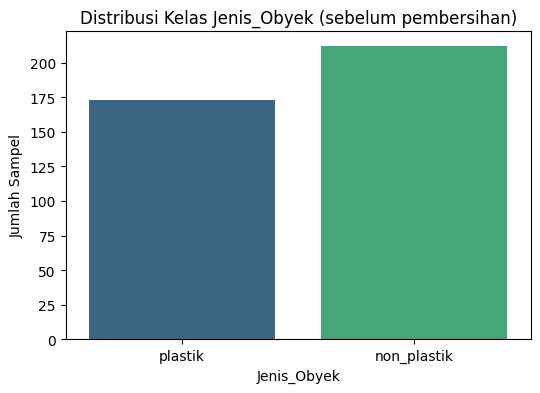

In [5]:
def load_and_validate_csv(config: dict, logger: logging.Logger) -> pd.DataFrame:
    """
    Load CSV dan validasi kolom wajib + normalisasi ekstensi file ke .png.

    Raises:
        FileNotFoundError: jika file CSV tidak ditemukan
        KeyError: jika kolom x_col / y_col tidak ada di CSV
        ValueError: jika CSV kosong atau class_names tidak cocok dengan isi y_col
    """
    csv_path = config["csv_path"]
    if not os.path.exists(csv_path):
        raise FileNotFoundError(
            f"File CSV tidak ditemukan di '{csv_path}'. "
            f"Periksa kembali path di CONFIG['csv_path'] dan pastikan Drive sudah ter-mount."
        )

    try:
        df = pd.read_csv(csv_path)
    except Exception as e:
        raise ValueError(f"Gagal membaca CSV '{csv_path}': {type(e).__name__}: {e}") from e

    if df.empty:
        raise ValueError(f"CSV '{csv_path}' berhasil dibaca tapi kosong (0 baris).")

    x_col, y_col = config["x_col"], config["y_col"]
    missing_cols = [c for c in (x_col, y_col) if c not in df.columns]
    if missing_cols:
        raise KeyError(
            f"Kolom wajib {missing_cols} tidak ditemukan di CSV. "
            f"Kolom yang tersedia: {df.columns.tolist()}. "
            f"Perbarui CONFIG['x_col']/CONFIG['y_col'] agar sesuai."
        )

    df[x_col] = df[x_col].apply(
        lambda f: f[:-4] + '.png' if isinstance(f, str) and f.lower().endswith('.tif') else f
    )

    unexpected_classes = set(df[y_col].unique()) - set(config["class_names"])
    if unexpected_classes:
        raise ValueError(
            f"Ditemukan kelas tak terduga di kolom '{y_col}': {unexpected_classes}. "
            f"Kelas yang diharapkan: {config['class_names']}."
        )

    logger.info(f"CSV berhasil dimuat: {len(df)} baris.")
    logger.info(f"Distribusi kelas:\n{df[y_col].value_counts().to_string()}")
    return df


def validate_images_exist(df: pd.DataFrame, images_dir: str, x_col: str, logger: logging.Logger,
                          sample_check: bool = True) -> None:
    """Validasi cepat bahwa direktori gambar ada dan berisi file yang direferensikan CSV
    (pemeriksaan penuh dilakukan di sel pembersihan data)."""
    if not os.path.isdir(images_dir):
        raise FileNotFoundError(
            f"Direktori gambar tidak ditemukan: '{images_dir}'. "
            f"Periksa CONFIG['images_dir_raw'] / CONFIG['images_dir_png']."
        )

    check_df = df.sample(min(50, len(df)), random_state=42) if sample_check else df
    missing = [f for f in check_df[x_col] if not os.path.exists(os.path.join(images_dir, f))]
    missing_ratio = len(missing) / len(check_df)
    if missing_ratio > 0.5:
        raise FileNotFoundError(
            f"{len(missing)}/{len(check_df)} file gambar sampel TIDAK ditemukan di '{images_dir}'. "
            f"Contoh file hilang: {missing[:5]}. Kemungkinan ekstensi belum dikonversi (.tif) "
            f"atau images_dir salah."
        )
    elif missing:
        logger.warning(f"{len(missing)}/{len(check_df)} file sampel tidak ditemukan -- lanjut, tapi periksa data.")
    else:
        logger.info(f"Validasi gambar OK: sampel {len(check_df)} file semuanya ditemukan di '{images_dir}'.")


df = load_and_validate_csv(CONFIG, logger)
validate_images_exist(df, CONFIG["images_dir_raw"], CONFIG["x_col"], logger)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=CONFIG['y_col'], hue=CONFIG['y_col'], palette='viridis', legend=False)
plt.title(f'Distribusi Kelas {CONFIG["y_col"]} (sebelum pembersihan)')
plt.xlabel(CONFIG['y_col'])
plt.ylabel('Jumlah Sampel')
plt.show()

## 3. Konversi TIF → PNG (idempoten)

Aman dijalankan berkali-kali: file yang sudah dikonversi dilewati.

In [6]:
def convert_tif_to_png(images_dir_raw: str, images_dir_png: str, df: pd.DataFrame, x_col: str,
                       logger: logging.Logger) -> str:
    """
    Konversi .tif -> .png satu kali, skip file yang sudah ada (idempoten).
    Coba rasterio dulu (lebih robust untuk GeoTIFF multiband), fallback ke PIL.

    Raises:
        RuntimeError: jika SEMUA file gagal dikonversi (bukan sebagian)
    """
    os.makedirs(images_dir_png, exist_ok=True)

    try:
        import rasterio
        use_rasterio = True
    except ImportError:
        logger.warning("Library 'rasterio' tidak tersedia, fallback ke PIL untuk konversi.")
        use_rasterio = False

    from PIL import Image

    converted, skipped, failed = 0, 0, 0
    failed_files = []

    for _, row in df.iterrows():
        raw_name = row[x_col]
        if not isinstance(raw_name, str):
            continue
        tif_name = raw_name.replace('.png', '.tif') if raw_name.lower().endswith('.png') else raw_name
        png_name = tif_name.replace('.tif', '.png') if tif_name.lower().endswith('.tif') else tif_name

        src_path = os.path.join(images_dir_raw, tif_name)
        dst_path = os.path.join(images_dir_png, png_name)

        if os.path.exists(dst_path):
            skipped += 1
            continue
        if not os.path.exists(src_path):
            failed += 1
            failed_files.append(tif_name)
            continue

        try:
            if use_rasterio:
                with rasterio.open(src_path) as src:
                    arr = src.read()
                    arr = np.transpose(arr, (1, 2, 0)) if arr.ndim == 3 else arr
                    if arr.dtype != np.uint8:
                        arr = ((arr - arr.min()) / (arr.max() - arr.min() + 1e-9) * 255).astype(np.uint8)
                    Image.fromarray(arr[:, :, :3] if arr.shape[-1] >= 3 else arr.squeeze()).save(dst_path, 'PNG')
            else:
                with Image.open(src_path) as img:
                    img.save(dst_path, 'PNG')
            converted += 1
        except Exception as e:
            failed += 1
            failed_files.append(f"{tif_name} ({type(e).__name__}: {e})")

    logger.info(f"Konversi TIF->PNG selesai. Berhasil: {converted}, sudah ada (skip): {skipped}, gagal: {failed}")
    if failed_files:
        logger.warning(f"Contoh file gagal/hilang: {failed_files[:5]}")

    if converted == 0 and skipped == 0:
        raise RuntimeError(
            f"SEMUA {failed} file gagal dikonversi. Periksa apakah '{images_dir_raw}' berisi file yang benar."
        )
    return images_dir_png


_png_dir = CONFIG["images_dir_png"]
_existing_png_count = (len([f for f in os.listdir(_png_dir) if f.lower().endswith('.png')])
                       if os.path.isdir(_png_dir) else 0)

if _existing_png_count >= len(df) * 0.9:
    logger.info(f"Folder PNG sudah berisi {_existing_png_count} file (>=90% dataset) -- lewati konversi.")
else:
    CONFIG["images_dir_png"] = convert_tif_to_png(
        CONFIG["images_dir_raw"], CONFIG["images_dir_png"], df, CONFIG["x_col"], logger
    )

df[CONFIG["x_col"]] = df[CONFIG["x_col"]].str.replace('.tif', '.png', regex=False)
IMAGES_DIR = CONFIG["images_dir_png"]

[12:11:43] INFO: Folder PNG sudah berisi 381 file (>=90% dataset) -- lewati konversi.


## 4. Audit integritas data (sebelum split)

Membuang `Patch_ID` ganda dan patch dengan isi piksel identik (patch kembar) **sebelum** split, supaya salinan yang sama tidak terpisah ke train dan test. Setiap baris yang dibuang dicatat di `dedup_report.csv`. Jumlah patch test akhir bergantung pada berapa baris yang dibuang di sini (pada run v7: 8 baris dibuang karena Patch_ID ganda berlabel bertentangan, sehingga n_test = 76; Acuan_3 tidak membuang apa pun sehingga 77) — pakai angka dari log, jangan angka dari versi lama.

In [7]:
from PIL import Image


def _pixel_md5(path: str) -> str:
    """Hash dari ISI PIKSEL (bukan byte file PNG), supaya metadata berbeda tidak menyamarkan duplikat."""
    with Image.open(path) as im:
        arr = np.asarray(im.convert("RGB"))
    return hashlib.md5(arr.tobytes()).hexdigest()


def audit_and_dedup(df: pd.DataFrame, images_dir: str, config: dict, logger: logging.Logger):
    """
    Audit integritas data SEBELUM split:
      1. Patch_ID ganda          -> simpan satu (label sama) atau buang semua (label bertentangan)
      2. File tidak terbaca      -> dibuang
      3. Isi piksel identik      -> simpan satu (label sama) atau buang semua (label bertentangan)
    Semua baris yang dibuang dicatat beserta alasannya di dedup_report.csv.
    Catatan: hanya duplikat PERSIS yang terdeteksi; patch yang bergeser 1 piksel / bertetangga
    ditangani oleh diagnostik spasial di sel berikutnya.
    """
    x, y = config["x_col"], config["y_col"]
    work = df.copy().reset_index(drop=True)
    n_input = len(work)
    removed = []

    def _log_removed(rows, reason):
        for _, r in rows.iterrows():
            removed.append({x: r[x], y: r[y], "alasan": reason})

    # --- 1. Patch_ID ganda ---
    if config["dedup_by_id"]:
        drop_idx = []
        for pid, g in work.groupby(x, sort=False):
            if len(g) == 1:
                continue
            if g[y].nunique() == 1:
                drop_idx.extend(g.index[1:])
                _log_removed(g.loc[g.index[1:]], "Patch_ID ganda (label sama) -- satu salinan dibuang")
            else:
                drop_idx.extend(g.index)
                _log_removed(g, "Patch_ID ganda dengan label BERTENTANGAN -- semua salinan dibuang")
        work = work.drop(index=drop_idx).reset_index(drop=True)

    # --- 2 & 3. File terbaca + isi piksel identik ---
    if config["dedup_by_content"]:
        hashes = []
        for _, r in work.iterrows():
            try:
                hashes.append(_pixel_md5(os.path.join(images_dir, r[x])))
            except Exception:
                hashes.append(None)
        work["_md5"] = hashes

        unreadable = work[work["_md5"].isna()]
        if len(unreadable):
            _log_removed(unreadable, "file gambar tidak ditemukan / tidak terbaca")
            work = work[work["_md5"].notna()].reset_index(drop=True)

        drop_idx = []
        for h, g in work.groupby("_md5", sort=False):
            if len(g) == 1:
                continue
            g = g.sort_values(x)
            if g[y].nunique() == 1:
                drop_idx.extend(g.index[1:])
                _log_removed(g.loc[g.index[1:]], f"isi piksel identik dengan {g[x].iloc[0]} (label sama)")
            else:
                drop_idx.extend(g.index)
                _log_removed(g, "isi piksel identik tetapi label BERTENTANGAN -- semua salinan dibuang")
        work = work.drop(index=drop_idx).drop(columns="_md5").reset_index(drop=True)

    removed_df = pd.DataFrame(removed, columns=[x, y, "alasan"])
    report_path = os.path.join(config["save_dir"], "dedup_report.csv")
    removed_df.to_csv(report_path, index=False)

    logger.info(f"Audit data: {n_input} baris masuk -> {len(work)} baris bersih "
                f"({len(removed_df)} baris dibuang). Rincian: {report_path}")
    if len(removed_df):
        display(removed_df.groupby("alasan").size().rename("jumlah").reset_index())
        print("Baris yang dibuang (cek Patch_ID ini di GIS; ID ganda berlabel bertentangan = tabel atribut atau nama berkas bentrok):")
        display(removed_df.sort_values([x, y]).reset_index(drop=True).head(60))
    else:
        logger.info("Tidak ada duplikat ID maupun duplikat isi piksel -- identitas partisi TIDAK berubah "
                    "dibanding versi sebelumnya (split_seed sama).")
    return work, removed_df


df_clean, df_removed = audit_and_dedup(df, IMAGES_DIR, CONFIG, logger)
df_clean[CONFIG["y_col"]].value_counts().to_frame("jumlah_setelah_pembersihan")

[12:11:56] INFO: Audit data: 385 baris masuk -> 377 baris bersih (8 baris dibuang). Rincian: /content/drive/MyDrive/project_BIMA26/model_comparison_outputs_isolated_v71/dedup_report.csv


,alasan,jumlah
0,Patch_ID ganda dengan label BERTENTANGAN -- se...,8


Baris yang dibuang (cek Patch_ID ini di GIS; ID ganda berlabel bertentangan = tabel atribut atau nama berkas bentrok):


,Patch_ID,Jenis_Obyek,alasan
0,tile_00184.png,non_plastik,Patch_ID ganda dengan label BERTENTANGAN -- se...
1,tile_00184.png,plastik,Patch_ID ganda dengan label BERTENTANGAN -- se...
2,tile_00185.png,non_plastik,Patch_ID ganda dengan label BERTENTANGAN -- se...
3,tile_00185.png,plastik,Patch_ID ganda dengan label BERTENTANGAN -- se...
4,tile_00201.png,non_plastik,Patch_ID ganda dengan label BERTENTANGAN -- se...
5,tile_00201.png,plastik,Patch_ID ganda dengan label BERTENTANGAN -- se...
6,tile_00202.png,non_plastik,Patch_ID ganda dengan label BERTENTANGAN -- se...
7,tile_00202.png,plastik,Patch_ID ganda dengan label BERTENTANGAN -- se...


,jumlah_setelah_pembersihan
Jenis_Obyek,
non_plastik,208
plastik,169


## 5. Split 3-arah: test terisolasi → validasi-internal → train

Test dikeluarkan lebih dulu dan tidak disentuh sampai prediksi akhir. Oversampling **tidak** dilakukan di sini.

In [8]:
def split_three_way(df: pd.DataFrame, config: dict, logger: logging.Logger):
    """
    Tahap 1 -- keluarkan TEST (test_size dari total, stratified), lalu dikunci.
    Tahap 2 -- dari sisanya, ambil validasi-internal (internal_val_size, stratified);
               sisanya = train. Validasi-internal HANYA untuk EarlyStopping /
               ReduceLROnPlateau / pemilihan best.pt YOLO.
    Tidak ada oversampling di sini: penyeimbangan kelas (bila ada) hanya diterapkan pada train
    SESUDAH split, di sel terpisah.
    """
    x, y, seed = config["x_col"], config["y_col"], config["split_seed"]
    try:
        df_trainval, df_test = train_test_split(
            df, test_size=config["test_size"], stratify=df[y], random_state=seed)
        df_train, df_val = train_test_split(
            df_trainval, test_size=config["internal_val_size"], stratify=df_trainval[y], random_state=seed)
    except ValueError as e:
        raise ValueError(f"Gagal melakukan stratified split: {e}. "
                         f"Kemungkinan salah satu kelas terlalu sedikit sampelnya.") from e

    df_train, df_val, df_test = (d.sort_values(x).reset_index(drop=True) for d in (df_train, df_val, df_test))

    # --- Pengaman integritas: partisi harus saling lepas dan lengkap ---
    s_tr, s_va, s_te = set(df_train[x]), set(df_val[x]), set(df_test[x])
    assert not (s_tr & s_va), "BOCOR: ada patch yang sama di train dan val"
    assert not (s_tr & s_te), "BOCOR: ada patch yang sama di train dan test"
    assert not (s_va & s_te), "BOCOR: ada patch yang sama di val dan test"
    assert len(s_tr) + len(s_va) + len(s_te) == len(df), "Jumlah patch tiga partisi tidak sama dengan total"
    for d in (df_train, df_val, df_test):
        assert d[x].is_unique, "Patch_ID tidak unik dalam satu partisi"

    n = len(df)
    logger.info(
        f"Split selesai: train={len(df_train)} ({len(df_train)/n:.1%}), "
        f"val-internal={len(df_val)} ({len(df_val)/n:.1%}), "
        f"test={len(df_test)} ({len(df_test)/n:.1%}) -- total {n}. Partisi saling lepas (diverifikasi)."
    )
    return df_train, df_val, df_test


def compute_split_hash(df_train, df_val, df_test, config) -> str:
    """Hash deterministik dari SEMUA partisi (nama file + label), bukan hanya test."""
    x, y = config["x_col"], config["y_col"]
    payload = {
        name: sorted(zip(d[x].astype(str).tolist(), d[y].astype(str).tolist()))
        for name, d in (("train", df_train), ("val", df_val), ("test", df_test))
    }
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode("utf-8")).hexdigest()


df_base_train, df_val, df_test = split_three_way(df_clean, CONFIG, logger)
SPLIT_HASH = compute_split_hash(df_base_train, df_val, df_test, CONFIG)
_ref_hash = CONFIG.get("reference_split_hash_prefix")
if _ref_hash:
    if SPLIT_HASH.startswith(_ref_hash):
        logger.info(f"Hash partisi cocok dengan run v7 ({_ref_hash}...): test set IDENTIK dengan v7.")
    else:
        logger.warning(f"Hash partisi ({SPLIT_HASH[:12]}...) BERBEDA dari run v7 ({_ref_hash}...). Test set TIDAK identik dengan v7: "
                       f"hasil v7 dan v7.1 tidak boleh dibandingkan langsung. Periksa apakah isi/urutan baris CSV berubah.")

# --- Tabel rincian partisi (untuk Tabel/Metode di naskah) ---
y_col = CONFIG["y_col"]
split_table = pd.DataFrame({
    "train": df_base_train[y_col].value_counts(),
    "val-internal": df_val[y_col].value_counts(),
    "test (terisolasi)": df_test[y_col].value_counts(),
}).fillna(0).astype(int)
split_table.loc["TOTAL"] = split_table.sum()
split_table["total"] = split_table.sum(axis=1)
display(split_table)
split_table.to_csv(os.path.join(CONFIG["save_dir"], "split_table.csv"))

with open(os.path.join(CONFIG["save_dir"], "split_overview.json"), "w") as f:
    json.dump({
        "code_version": CODE_VERSION,
        "split_hash": SPLIT_HASH,
        "split_seed": CONFIG["split_seed"],
        "n_total": int(len(df_clean)),
        "n_train": int(len(df_base_train)), "n_val_internal": int(len(df_val)), "n_test": int(len(df_test)),
        "train_filenames": df_base_train[CONFIG["x_col"]].tolist(),
        "val_filenames": df_val[CONFIG["x_col"]].tolist(),
        "test_filenames": df_test[CONFIG["x_col"]].tolist(),
    }, f, indent=2)
logger.info(f"Split hash (train+val+test): {SPLIT_HASH[:16]}... | rincian partisi disimpan ke save_dir.")

[12:11:56] INFO: Split selesai: train=255 (67.6%), val-internal=46 (12.2%), test=76 (20.2%) -- total 377. Partisi saling lepas (diverifikasi).
[12:11:56] INFO: Hash partisi cocok dengan run v7 (5b16f7467b08...): test set IDENTIK dengan v7.


,train,val-internal,test (terisolasi),total
Jenis_Obyek,,,,
non_plastik,141,25,42,208
plastik,114,21,34,169
TOTAL,255,46,76,377


[12:12:00] INFO: Split hash (train+val+test): 5b16f7467b08ab9d... | rincian partisi disimpan ke save_dir.


### Diagnostik korelasi spasial (test/val → train terdekat)

Bukan koreksi, melainkan bukti: seberapa sering patch uji bersebelahan langsung dengan patch latih dan berlabel sama. Hasilnya menentukan apakah perlu split berbasis blok spasial atau cukup dicatat sebagai keterbatasan.

In [9]:
_COORD_CANDIDATES = [
    ("lon", "lat"), ("longitude", "latitude"), ("long", "lat"), ("x", "y"),
    ("x_coord", "y_coord"), ("xcoord", "ycoord"), ("easting", "northing"),
    ("centroid_x", "centroid_y"), ("center_x", "center_y"), ("x_center", "y_center"),
]


def find_coord_cols(df: pd.DataFrame, config: dict):
    if config.get("spatial_cols"):
        cols = tuple(config["spatial_cols"])
        return cols if all(c in df.columns for c in cols) else None
    lower = {c.lower(): c for c in df.columns}
    for a, b in _COORD_CANDIDATES:
        if a in lower and b in lower:
            return lower[a], lower[b]
    return None


def spatial_leakage_diagnostic(df_train, df_val, df_test, config, logger):
    """
    Diagnostik (BUKAN koreksi): seberapa dekat tiap patch test/val dengan patch train terdekat?
    Patch bertetangga biasanya mirip (autokorelasi spasial); bila sebagian besar patch test
    bersebelahan langsung dengan patch train berlabel sama, skor test cenderung optimistis dan
    perlu diungkapkan sebagai keterbatasan -- atau split diganti menjadi split berbasis blok spasial.
    """
    try:
        pool = pd.concat([df_train, df_val, df_test], ignore_index=True)
        cols = find_coord_cols(pool, config)
        if cols is None:
            logger.warning(
                "Diagnostik spasial DILEWATI: kolom koordinat tidak ditemukan otomatis. "
                f"Kolom CSV: {pool.columns.tolist()}. Isi CONFIG['spatial_cols'] = ['kolom_x', 'kolom_y'] "
                "(bujur/lintang dalam derajat, atau meter) lalu jalankan ulang dari sel CONFIG."
            )
            return None
        cx, cy = cols

        def to_xy_m(d):
            xs = pd.to_numeric(d[cx], errors="coerce").to_numpy(dtype=float)
            ys = pd.to_numeric(d[cy], errors="coerce").to_numpy(dtype=float)
            if np.nanmax(np.abs(xs)) <= 180 and np.nanmax(np.abs(ys)) <= 90:      # derajat
                lat0 = np.deg2rad(np.nanmean(ys))
                return np.c_[xs * 111320.0 * np.cos(lat0), ys * 110540.0]
            return np.c_[xs, ys]                                                    # sudah meter

        for name, d in (("train", df_train), ("val", df_val), ("test", df_test)):
            if pd.to_numeric(d[cx], errors="coerce").isna().any() or pd.to_numeric(d[cy], errors="coerce").isna().any():
                logger.warning(f"Diagnostik spasial DILEWATI: koordinat tidak numerik/kosong pada partisi {name}.")
                return None

        from sklearn.neighbors import NearestNeighbors
        xy_train = to_xy_m(df_train)
        nn = NearestNeighbors(n_neighbors=1).fit(xy_train)

        patch = config["patch_size_m"]
        rows, summary = [], []
        for name, d in (("test", df_test), ("val-internal", df_val)):
            dist, idx = nn.kneighbors(to_xy_m(d))
            dist = dist.ravel()
            nb_label = df_train[config["y_col"]].to_numpy()[idx.ravel()]
            same = (nb_label == d[config["y_col"]].to_numpy())
            adjacent = dist <= 1.5 * patch      # bersebelahan langsung (termasuk diagonal ±1.41 x patch)
            near3 = dist <= 3.0 * patch
            summary.append({
                "partisi": name, "n": len(d),
                "jarak_min_m": round(float(dist.min()), 1),
                "jarak_median_m": round(float(np.median(dist)), 1),
                "%_bersebelahan(<=1.5 patch)": round(100 * adjacent.mean(), 1),
                "%_dalam_3_patch": round(100 * near3.mean(), 1),
                "%_label_tetangga_sama(semua)": round(100 * same.mean(), 1),
                "%_label_tetangga_sama(hanya yg bersebelahan)": round(100 * same[adjacent].mean(), 1) if adjacent.any() else np.nan,
            })
            rows.append(pd.DataFrame({
                config["x_col"]: d[config["x_col"]].to_numpy(), "partisi": name,
                "jarak_ke_train_terdekat_m": dist, "label_tetangga_sama": same,
            }))
        summary_df = pd.DataFrame(summary)
        display(summary_df)
        pd.concat(rows).to_csv(os.path.join(config["save_dir"], "spatial_nn_distance.csv"), index=False)
        summary_df.to_csv(os.path.join(config["save_dir"], "spatial_nn_summary.csv"), index=False)
        logger.info(f"Diagnostik spasial memakai kolom koordinat: {cols}. Hasil disimpan ke save_dir.")
        return summary_df
    except Exception as e:  # diagnostik tidak boleh menggagalkan pipeline
        logger.warning(f"Diagnostik spasial gagal dijalankan ({type(e).__name__}: {e}) -- dilewati.")
        return None


spatial_summary = spatial_leakage_diagnostic(df_base_train, df_val, df_test, CONFIG, logger)

[12:12:00] WARNING: Diagnostik spasial DILEWATI: kolom koordinat tidak ditemukan otomatis. Kolom CSV: ['Patch_ID', 'Jenis_Obyek', 'Nilai']. Isi CONFIG['spatial_cols'] = ['kolom_x', 'kolom_y'] (bujur/lintang dalam derajat, atau meter) lalu jalankan ulang dari sel CONFIG.


### Penyeimbangan kelas (satu mekanisme saja)

Data asli ±55:45 (non_plastik:plastik). Pada Acuan_3, oversampling `ceil()-1` menaikkan plastik melewati non_plastik lalu `class_weight` membaliknya lagi. Di v7 hanya SATU mekanisme aktif sesuai `CONFIG["balance_mode"]`.

In [10]:
def compute_class_weights_from_df(df_train: pd.DataFrame, config: dict, logger: logging.Logger) -> dict:
    """class_weight 'balanced' dari label train (kunci = indeks kelas bertipe int)."""
    labels = df_train[config["y_col"]].map(CLASS_TO_IDX).to_numpy()
    classes = np.array(sorted(CLASS_TO_IDX.values()))
    weights = compute_class_weight(class_weight="balanced", classes=classes, y=labels)
    cw = {int(c): float(w) for c, w in zip(classes, weights)}
    logger.info(f"class_weight (balanced) dari {len(df_train)} patch train: {cw}")
    return cw


def oversample_to_equal(df_train: pd.DataFrame, config: dict, logger: logging.Logger) -> pd.DataFrame:
    """Replikasi baris kelas non-mayoritas SAMPAI JUMLAH SAMA (tidak overshoot seperti ceil()-1)."""
    x, y = config["x_col"], config["y_col"]
    counts = df_train[y].value_counts()
    target = int(counts.max())
    pieces = [df_train]
    for cname, n_c in counts.items():
        n_extra = target - int(n_c)
        if n_extra > 0:
            rows = df_train[df_train[y] == cname].sort_values(x)
            pieces.append(rows.iloc[[i % len(rows) for i in range(n_extra)]])
    out = pd.concat(pieces, ignore_index=True).sample(frac=1.0, random_state=config["split_seed"]).reset_index(drop=True)
    logger.info(f"Oversampling ke jumlah sama: {len(df_train)} -> {len(out)} baris train. "
                f"Distribusi: {out[y].value_counts().to_dict()}")
    return out


_bm = CONFIG["balance_mode"]
if _bm == "oversample":
    df_fit = oversample_to_equal(df_base_train, CONFIG, logger)
    class_weights_dict = None                       # TIDAK dobel dengan class_weight
elif _bm == "class_weight":
    df_fit = df_base_train.copy()
    class_weights_dict = compute_class_weights_from_df(df_base_train, CONFIG, logger)
else:
    df_fit = df_base_train.copy()
    class_weights_dict = None
    logger.info("balance_mode='none': tanpa penyeimbangan kelas.")

counts_fit = df_fit[CONFIG["y_col"]].value_counts()
logger.info(f"Train untuk fitting model: {len(df_fit)} baris | distribusi {counts_fit.to_dict()} "
            f"| rasio mayoritas:minoritas = {counts_fit.max() / counts_fit.min():.2f}")

[12:12:00] INFO: class_weight (balanced) dari 255 patch train: {0: 0.9042553191489362, 1: 1.118421052631579}
[12:12:00] INFO: Train untuk fitting model: 255 baris | distribusi {'non_plastik': 141, 'plastik': 114} | rasio mayoritas:minoritas = 1.24


## 6. Definisi fungsi (tidak ada training di bagian ini)

In [11]:
# ==========================================
# DEFINISI: generator, arsitektur, training Keras
# (sel ini hanya mendefinisikan fungsi -- tidak ada training di sini)
# ==========================================

def build_generators(df_fit, df_val, df_test, images_dir, config, seed, logger):
    """
    train : augmentasi, shuffle (seed training)
    val   : tanpa augmentasi -- validasi-internal (EarlyStopping/ReduceLROnPlateau)
    test  : tanpa augmentasi -- TERISOLASI, hanya dipakai untuk prediksi akhir
    train_eval : data train tanpa augmentasi (diagnostik: akurasi train pada mode inferensi vs validasi)
    """
    train_datagen = ImageDataGenerator(
        rescale=1.0 / 255.0, rotation_range=30, width_shift_range=0.15, height_shift_range=0.15,
        shear_range=0.2, zoom_range=0.15, horizontal_flip=True, vertical_flip=True, fill_mode='nearest',
    )
    eval_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

    def _flow(datagen, d, shuffle, **kw):
        return datagen.flow_from_dataframe(
            dataframe=d, directory=images_dir, x_col=config["x_col"], y_col=config["y_col"],
            target_size=config["img_size"], batch_size=config["batch_size"],
            class_mode='binary', classes=config["class_names"], shuffle=shuffle, **kw)

    try:
        train_gen = _flow(train_datagen, df_fit, True, seed=seed)
        val_gen = _flow(eval_datagen, df_val, False)
        test_gen = _flow(eval_datagen, df_test, False)
        train_eval_gen = _flow(eval_datagen, df_fit, False)   # train TANPA augmentasi, hanya untuk diagnostik
    except Exception as e:
        raise RuntimeError(f"Gagal membangun ImageDataGenerator: {type(e).__name__}: {e}") from e

    # flow_from_dataframe diam-diam membuang baris yang file-nya tidak ada -> cek eksplisit
    for name, g, d in (("train", train_gen, df_fit), ("val", val_gen, df_val), ("test", test_gen, df_test), ("train-eval", train_eval_gen, df_fit)):
        if g.samples != len(d):
            raise RuntimeError(f"Generator '{name}' hanya menemukan {g.samples}/{len(d)} gambar -- "
                               f"periksa nama file di CSV vs folder '{images_dir}'.")
    logger.info(f"Generator siap: train={train_gen.samples}, val-internal={val_gen.samples}, "
                f"test(terisolasi)={test_gen.samples}.")
    return train_gen, val_gen, test_gen, train_eval_gen


def build_custom_cnn(input_shape, learning_rate=1e-3):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(32, (3, 3), padding="same", activation="relu", kernel_regularizer=regularizers.l2(0.001)),
        layers.BatchNormalization(),
        layers.Conv2D(32, (3, 3), padding="same", activation="relu", kernel_regularizer=regularizers.l2(0.001)),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(64, (3, 3), padding="same", activation="relu", kernel_regularizer=regularizers.l2(0.001)),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
        layers.Dropout(0.4),
        layers.Dense(1, activation='sigmoid'),
    ])
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='binary_crossentropy', metrics=['accuracy'])
    return model


def build_mobilenet_model(input_shape, weights, learning_rate=1e-4, resize_to=(96, 96)):
    """MobileNetV2 (ImageNet) + head; patch 32x32 di-upscale INTERNAL ke 96x96 (layer Resizing).
    Base dibekukan dulu; fine-tuning dilakukan terpisah oleh set_finetune_trainable()."""
    inputs = layers.Input(shape=input_shape)
    x = layers.Resizing(resize_to[0], resize_to[1], interpolation="bilinear", name="upscale_for_mobilenet")(inputs)
    try:
        base_model = MobileNetV2(input_shape=(resize_to[0], resize_to[1], input_shape[2]),
                                 include_top=False, weights=weights)
    except Exception as e:
        raise RuntimeError(f"Gagal memuat MobileNetV2 (weights={weights}): {e}. "
                           f"Periksa koneksi internet (bobot ImageNet diunduh saat pertama kali).") from e
    base_model.trainable = False
    x = base_model(x)
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)
    output = Dense(1, activation='sigmoid')(x)
    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='binary_crossentropy', metrics=['accuracy'])
    return model, base_model


def build_vgg16_model(input_shape, weights, learning_rate=1e-4):
    try:
        base_model = VGG16(input_shape=input_shape, include_top=False, weights=weights)
    except Exception as e:
        raise RuntimeError(f"Gagal memuat VGG16 (weights={weights}): {e}. "
                           f"Periksa koneksi internet (bobot ImageNet diunduh saat pertama kali).") from e
    base_model.trainable = False
    x = GlobalAveragePooling2D()(base_model.output)
    x = Dense(128, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)
    output = Dense(1, activation='sigmoid')(x)
    model = Model(inputs=base_model.input, outputs=output)
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='binary_crossentropy', metrics=['accuracy'])
    return model, base_model


def count_params(model):
    n_train = int(sum(int(np.prod(w.shape)) for w in model.trainable_weights))
    n_all = int(sum(int(np.prod(w.shape)) for w in model.weights))
    return n_train, n_all


def set_finetune_trainable(base_model, num_unfreeze: int):
    """
    Buka `num_unfreeze` lapisan terakhir base model untuk fine-tuning. Lapisan BatchNormalization
    tetap dibekukan (BN pada batch kecil merusak statistik ImageNet).
    base_model.trainable=True DIBUKA DULU: bila pembungkus masih False, perubahan `trainable`
    pada lapisan di dalamnya bisa tidak berefek (tergantung versi Keras).
    """
    base_model.trainable = True
    n = len(base_model.layers)
    cut = max(0, n - num_unfreeze)
    n_bn_frozen = 0
    for i, layer in enumerate(base_model.layers):
        if i < cut:
            layer.trainable = False
        elif isinstance(layer, BatchNormalization):
            layer.trainable = False
            n_bn_frozen += 1
        else:
            layer.trainable = True
    return n, cut, n_bn_frozen


class EpochLogger(Callback):
    """Log ringkas tiap `every` epoch (training memakai verbose=0 agar output notebook tidak membengkak)."""
    def __init__(self, name, every=10):
        super().__init__()
        self.name, self.every = name, every

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every == 0 and logs:
            logger.info(f"[{self.name}] epoch {epoch + 1}: loss={logs.get('loss', float('nan')):.4f} "
                        f"acc={logs.get('accuracy', float('nan')):.4f} "
                        f"val_loss={logs.get('val_loss', float('nan')):.4f} "
                        f"val_acc={logs.get('val_accuracy', float('nan')):.4f}")


def train_keras_model(model, model_name, train_gen, monitor_gen, config, class_weights, patience):
    """Training dengan EarlyStopping + ReduceLROnPlateau yang memantau `monitor_gen`
    (= validasi-internal pada lengan bersih)."""
    # start_from_epoch (Keras >= 3): selama warm-up EarlyStopping tidak memantau dan TIDAK menyimpan bobot terbaik,
    # sehingga checkpoint tidak bisa berasal dari epoch awal (mis. epoch 1 saat statistik BatchNorm belum stabil).
    es = EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True,
                       start_from_epoch=config["es_start_from_epoch"], verbose=0)
    callbacks = [
        es,
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=0),
        EpochLogger(model_name),
    ]
    logger.info(f"Training '{model_name}' -- epochs maks={config['epochs']}, batch={config['batch_size']}, "
                f"patience={patience}, es_start_from_epoch={config['es_start_from_epoch']}, "
                f"class_weight={'ya' if class_weights else 'tidak'}")
    try:
        history = model.fit(train_gen, epochs=config["epochs"], validation_data=monitor_gen,
                            callbacks=callbacks, class_weight=class_weights, verbose=0)
    except tf.errors.ResourceExhaustedError as e:
        logger.error(f"[{model_name}] memori habis (OOM). Turunkan CONFIG['batch_size']. {e}")
        raise
    except Exception as e:
        logger.error(f"[{model_name}] training gagal: {type(e).__name__}: {e}")
        raise
    if not history.history.get("loss") or np.isnan(history.history["loss"][-1]):
        logger.warning(f"[{model_name}] loss akhir NaN / history kosong -- training tidak stabil.")
    be = getattr(es, "best_epoch", None)
    logger.info(f"Training '{model_name}' selesai: {len(history.history['loss'])} epoch dijalankan"
                + (f"; bobot akhir = epoch {int(be) + 1} (val_loss terendah, dipilih hanya dari epoch > {config['es_start_from_epoch']})."
                   if be is not None else "."))
    return history


def train_two_phase(kind, input_shape, train_gen, monitor_gen, config, class_weights):
    """MobileNetV2 / VGG16: fase 1 (base beku) lalu fase 2 (fine-tuning). Berhenti dengan error
    bila fase 2 ternyata tidak membuka parameter baru (fine-tuning tidak aktif)."""
    if kind == "mobilenet":
        name = "MobileNetV2"
        model, base = build_mobilenet_model(input_shape, config["imagenet_weights"])
        ft_lr = config["mobilenet_finetune_lr"]
        num_unfreeze = min(len(base.layers),
                           max(config["mobilenet_min_unfreeze"], int(len(base.layers) * config["mobilenet_unfreeze_fraction"])))
    else:
        name = "VGG16"
        model, base = build_vgg16_model(input_shape, config["imagenet_weights"])
        ft_lr = config["vgg_finetune_lr"]
        num_unfreeze = len(base.layers)            # full fine-tune (eksplisit)

    t0, a0 = count_params(model)
    logger.info(f"[{name}] fase 1 (base beku): parameter trainable={t0:,} dari {a0:,}")
    h1 = train_keras_model(model, f"{name} (frozen)", train_gen, monitor_gen, config, class_weights,
                           config["default_patience"])

    n_layers, cut, n_bn = set_finetune_trainable(base, num_unfreeze)
    model.compile(optimizer=Adam(learning_rate=ft_lr), loss='binary_crossentropy', metrics=['accuracy'])
    t1, _ = count_params(model)
    logger.info(f"[{name}] fase 2 (fine-tune): {n_layers - cut} dari {n_layers} lapisan base dibuka "
                f"({n_bn} BatchNorm tetap beku) -> parameter trainable={t1:,} (fase 1: {t0:,}), lr={ft_lr}")
    if t1 <= t0:
        raise RuntimeError(f"[{name}] fine-tuning TIDAK aktif: parameter trainable tidak bertambah "
                           f"({t0:,} -> {t1:,}). Periksa versi Keras / set_finetune_trainable().")
    h2 = train_keras_model(model, f"{name} (fine-tuned)", train_gen, monitor_gen, config, class_weights,
                           config["default_patience"])
    return model, h1, h2


def join_histories(*histories, keys=("accuracy", "val_accuracy", "loss", "val_loss")):
    """Gabungkan fase-fase training jadi satu dict (list float) + indeks batas fase."""
    out = {k: [] for k in keys}
    boundary = None
    for i, h in enumerate(histories):
        if h is None:
            continue
        if i > 0 and boundary is None:
            boundary = len(out[keys[0]])
        for k in keys:
            out[k].extend(float(v) for v in h.history.get(k, []))
    out["phase_boundary"] = boundary
    return out


def predict_keras(model, generator):
    generator.reset()
    prob = np.asarray(model.predict(generator, verbose=0)).reshape(-1)
    if len(prob) != generator.samples:
        raise RuntimeError(f"Jumlah prediksi ({len(prob)}) != jumlah sampel generator ({generator.samples}).")
    return prob

In [12]:
# ==========================================
# DEFINISI: YOLOv8-cls (folder dataset + training di SUBPROSES)
# ==========================================
# YOLO dilatih di proses terpisah (subprocess), bukan di dalam kernel notebook:
#   1) menghindari bentrok pustaka native TensorFlow vs PyTorch dalam satu proses
#      (bisa menyebabkan crash/segfault tanpa pesan) dan rebutan memori GPU antar-framework;
#   2) memori GPU TensorFlow dibebaskan antar-tahap secara otomatis.
# Notebook hanya membaca CSV prediksi dan results.csv yang ditulis oleh worker.
import importlib.util
import subprocess

if importlib.util.find_spec("ultralytics") is None:
    logger.info("Paket 'ultralytics' belum terpasang -- memasang (pip install ultralytics)...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)

YOLO_WORKER_CODE = r'''
import sys, os, json
from pathlib import Path
import pandas as pd

args = json.load(open(sys.argv[1]))
import torch
from ultralytics import YOLO

device = 0 if torch.cuda.is_available() else "cpu"
model = YOLO(args["arch"])
model.train(
    data=args["data"], epochs=args["epochs"], imgsz=args["imgsz"], batch=args["batch"],
    lr0=args["lr0"], lrf=args["lrf"], cos_lr=True, warmup_epochs=3, patience=args["patience"],
    dropout=0.2, degrees=15.0, flipud=0.3, fliplr=0.5, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0,
    seed=args["seed"], device=device, project=args["project"], name=args["name"], exist_ok=True,
    verbose=False, plots=False, workers=args["workers"],
)
run_dir = Path(model.trainer.save_dir)
best = run_dir / "weights" / "best.pt"
if not best.exists():
    raise RuntimeError("best.pt tidak ditemukan: %s" % best)

eval_model = YOLO(str(best))
class_names = args["class_names"]
cls_idx = {n: i for i, n in enumerate(class_names)}
pos_name = class_names[1]


def predict_folder(split_dir):
    paths, truths = [], []
    for cn in class_names:
        d = os.path.join(split_dir, cn)
        for f in sorted(os.listdir(d)):
            paths.append(os.path.join(d, f))
            truths.append(cls_idx[cn])
    if not paths:
        raise RuntimeError("Tidak ada gambar di %s" % split_dir)
    rows = []
    for i in range(0, len(paths), 64):
        sub = paths[i:i + 64]
        results = eval_model.predict(sub, imgsz=args["imgsz"], device=device, verbose=False)
        if len(results) != len(sub):
            raise RuntimeError("Jumlah hasil prediksi YOLO != jumlah gambar")
        for p, t, r in zip(sub, truths[i:i + 64], results):
            probs = r.probs.data.detach().cpu().numpy()
            by_name = {r.names[k]: float(probs[k]) for k in range(len(probs))}
            pred_name = max(by_name, key=by_name.get)
            rows.append({"filename": os.path.basename(p), "y_true_yolo": t,
                         "pred_yolo": cls_idx[pred_name], "prob_yolo": by_name[pos_name]})
    return pd.DataFrame(rows)


out = Path(args["out_dir"])
predict_folder(os.path.join(args["data"], "test")).to_csv(out / "yolo_test_preds.csv", index=False)
if args.get("predict_val"):
    predict_folder(os.path.join(args["data"], "val")).to_csv(out / "yolo_val_preds.csv", index=False)

import ultralytics
with open(out / "yolo_worker_result.json", "w") as f:
    json.dump({"best": str(best), "results_csv": str(run_dir / "results.csv"), "device": str(device),
               "ultralytics": ultralytics.__version__, "torch": torch.__version__}, f)
print("YOLO_WORKER_DONE")
'''


def run_yolo_worker(args: dict, out_dir: str, log_path: str) -> dict:
    """Latih + prediksi YOLOv8-cls di subproses; output proses disimpan ke log_path (bukan ke notebook)."""
    worker_path = os.path.join(CONFIG["save_dir"], "yolo_worker.py")
    with open(worker_path, "w", encoding="utf-8") as f:
        f.write(YOLO_WORKER_CODE)
    args_path = os.path.join(out_dir, "yolo_worker_args.json")
    with open(args_path, "w") as f:
        json.dump(args, f)
    result_path = os.path.join(out_dir, "yolo_worker_result.json")
    if os.path.exists(result_path):
        os.remove(result_path)
    with open(log_path, "w", encoding="utf-8") as lf:
        proc = subprocess.run([sys.executable, worker_path, args_path], stdout=lf, stderr=subprocess.STDOUT)
    if proc.returncode != 0 or not os.path.exists(result_path):
        with open(log_path, encoding="utf-8", errors="replace") as lf:
            tail = lf.read()[-3000:]
        raise RuntimeError(f"Worker YOLO gagal (exit code {proc.returncode}). Ekor log ({log_path}):\n{tail}")
    with open(result_path) as f:
        return json.load(f)


def prepare_yolo_folder_structure(df_fit, df_val, df_test, images_dir, yolo_dir, config,
                                  class_weights_dict, logger, val_source="val"):
    """
    Bangun dataset YOLO-cls: yolo_dir/{train,val,test}/<kelas>/<file>.png

    * Folder dihapus lalu dibangun ulang -> tidak ada sisa file dari run sebelumnya.
    * Baris duplikat (hasil replikasi) diberi nama tujuan UNIK (_copyN); tanpa ini file bernama
      sama saling menimpa dan replikasi tidak pernah sampai ke YOLO.
    * balance_mode='class_weight': YOLO tidak punya class_weight, jadi bobot 'balanced' diwujudkan
      dengan replikasi gambar kelas minoritas di folder TRAIN saja (jumlah kelas disamakan).
    * Ultralytics memakai 'train' + 'val' selama training; 'test' tidak pernah dilihat saat training.
    * val_source='test' hanya untuk lengan "protokol lama" (val = test) -- jangan dipakai untuk hasil utama.
    """
    x, y = config["x_col"], config["y_col"]
    class_names = config["class_names"]

    if os.path.exists(yolo_dir):
        shutil.rmtree(yolo_dir)
    for split in ("train", "val", "test"):
        for cn in class_names:
            os.makedirs(os.path.join(yolo_dir, split, cn), exist_ok=True)

    train_rows = df_fit
    n_extra = 0
    if config["balance_mode"] == "class_weight" and class_weights_dict:
        counts = df_fit[y].value_counts()
        w = {cn: class_weights_dict[CLASS_TO_IDX[cn]] for cn in class_names}
        w_min = min(w.values())
        pieces = []
        for cn in class_names:
            extra = int(round((w[cn] / w_min - 1.0) * int(counts[cn])))
            if extra > 0:
                rows = df_fit[df_fit[y] == cn].sort_values(x)
                pieces.append(rows.iloc[[i % len(rows) for i in range(extra)]])
        if pieces:
            extra_df = pd.concat(pieces)
            n_extra = len(extra_df)
            train_rows = pd.concat([df_fit, extra_df], ignore_index=True)

    val_rows = df_val if val_source == "val" else df_test

    expected = {}
    for split, rows in (("train", train_rows), ("val", val_rows), ("test", df_test)):
        seen = {}
        for _, r in rows.iterrows():
            fname, cname = r[x], r[y]
            k = seen.get(fname, 0)
            seen[fname] = k + 1
            stem, ext = os.path.splitext(fname)
            dst_name = fname if k == 0 else f"{stem}_copy{k}{ext}"
            src = os.path.join(images_dir, fname)
            if not os.path.exists(src):
                raise FileNotFoundError(f"File sumber tidak ada: {src}")
            shutil.copy2(src, os.path.join(yolo_dir, split, cname, dst_name))
            expected[(split, cname)] = expected.get((split, cname), 0) + 1

    # --- Verifikasi: jumlah file fisik harus sama dengan jumlah baris ---
    info = {}
    for split in ("train", "val", "test"):
        for cn in class_names:
            actual = len(os.listdir(os.path.join(yolo_dir, split, cn)))
            exp = expected.get((split, cn), 0)
            if actual != exp:
                raise RuntimeError(f"Folder YOLO {split}/{cn}: {actual} file, seharusnya {exp} -- ada file saling menimpa.")
            info[f"{split}/{cn}"] = actual
    test_files = {f for cn in class_names for f in os.listdir(os.path.join(yolo_dir, "test", cn))}
    if test_files != set(df_test[x]):
        raise RuntimeError("Isi folder test YOLO tidak sama dengan df_test.")
    train_orig = {re.sub(r"_copy\d+(?=\.[^.]+$)", "", f)
                  for cn in class_names for f in os.listdir(os.path.join(yolo_dir, "train", cn))}
    if train_orig & test_files:
        raise RuntimeError("BOCOR: ada gambar test di folder train YOLO.")

    logger.info(f"Dataset YOLO siap di {yolo_dir} (val_source='{val_source}'): "
                + ", ".join(f"{k}={v}" for k, v in info.items()) + f" | replikasi train: +{n_extra}")
    return info

[12:12:00] INFO: Paket 'ultralytics' belum terpasang -- memasang (pip install ultralytics)...


In [13]:
# ==========================================
# FUNGSI UTAMA: latih 4 model untuk SATU seed, simpan prediksi/histori (cache per seed)
# ==========================================
_FP_KEYS = ["img_size", "batch_size", "epochs", "imagenet_weights", "default_patience", "cnn_patience",
            "mobilenet_unfreeze_fraction", "mobilenet_min_unfreeze", "mobilenet_finetune_lr", "vgg_finetune_lr",
            "balance_mode", "yolo_model_arch", "yolo_epochs", "yolo_imgsz", "yolo_batch", "yolo_lr0",
            "yolo_lrf", "yolo_patience", "yolo_workers", "es_start_from_epoch"]


def make_fingerprint(config, split_hash, arm):
    """Cache hanya valid bila SEMUA ini sama: partisi (train+val+test), hyper-parameter, lengan, versi kode."""
    payload = {k: config[k] for k in _FP_KEYS}
    payload.update(split_hash=split_hash, arm=arm, code_version=CODE_VERSION)
    return hashlib.sha256(json.dumps(payload, sort_keys=True, default=str).encode("utf-8")).hexdigest()


def _seed_dir(arm, seed):
    d = os.path.join(CONFIG["save_dir"], f"arm_{arm}", f"seed_{seed}")
    os.makedirs(d, exist_ok=True)
    return d


def _load_cached_seed(arm, seed, fingerprint):
    d = _seed_dir(arm, seed)
    meta_p, preds_p, hist_p = (os.path.join(d, n) for n in ("meta.json", "preds.csv", "histories.json"))
    if CONFIG.get("force_retrain") or not all(os.path.exists(p) for p in (meta_p, preds_p, hist_p)):
        return None
    try:
        with open(meta_p) as f:
            meta = json.load(f)
        if meta.get("fingerprint") != fingerprint:
            return None
        with open(hist_p) as f:
            histories = json.load(f)
        return {"preds": pd.read_csv(preds_p), "histories": histories, "meta": meta,
                "yolo_results_csv": meta.get("yolo_results_csv")}
    except Exception:
        return None


def run_one_seed(seed, arm, ctx):
    """
    arm='clean' : EarlyStopping/ReduceLROnPlateau/best.pt memantau validasi-internal (protokol yang dilaporkan)
    arm='leaky' : memantau TEST (protokol lama) pada train set yang SAMA -- hanya untuk mengukur bias
    Test hanya dipakai untuk prediksi akhir (lengan 'clean'); lihat catatan di tiap lengan.
    """
    fingerprint = make_fingerprint(CONFIG, ctx["split_hash"], arm)
    cached = _load_cached_seed(arm, seed, fingerprint)
    if cached is not None:
        logger.info(f"[seed {seed} | {arm}] dimuat dari cache (fingerprint cocok) -- training dilewati.")
        return cached

    t_start = time.time()
    out_dir = _seed_dir(arm, seed)
    input_shape = (CONFIG["img_size"][0], CONFIG["img_size"][1], 3)
    cw = ctx["class_weights_dict"]
    yolo_dir = ctx["yolo_dir_clean"] if arm == "clean" else ctx["yolo_dir_leaky"]

    train_gen, val_gen, test_gen, train_eval_gen = build_generators(
        ctx["df_fit"], ctx["df_val"], ctx["df_test"], ctx["images_dir"], CONFIG, seed, logger)
    monitor_gen = val_gen if arm == "clean" else test_gen

    histories, val_acc, collapsed, train_acc_infer = {}, {}, {}, {}
    probs = {}

    def _val_diag(model, name):
        p = predict_keras(model, val_gen)
        acc = float(np.mean((p > 0.5).astype(int) == val_gen.classes))
        frac_pos = float(np.mean(p > 0.5))
        collapsed[name] = bool(frac_pos < 0.05 or frac_pos > 0.95)
        if collapsed[name]:
            logger.warning(f"[seed {seed} | {name}] KOLAPS? model memprediksi satu kelas saja pada validasi-internal "
                           f"(fraksi 'plastik'={frac_pos:.2f}, val_acc={acc:.3f}).")
        val_acc[name] = acc
        ptr = predict_keras(model, train_eval_gen)
        train_acc_infer[name] = float(np.mean((ptr > 0.5).astype(int) == train_eval_gen.classes))
        logger.info(f"[seed {seed} | {name}] akurasi TRAIN tanpa augmentasi (mode inferensi)={train_acc_infer[name]:.3f} | "
                    f"validasi-internal={acc:.3f}")

    # ---------------- Model 1: Custom CNN ----------------
    tf.keras.backend.clear_session(); set_global_seed(seed)
    cnn = build_custom_cnn(input_shape)
    h = train_keras_model(cnn, "Custom CNN", train_gen, monitor_gen, CONFIG, cw, CONFIG["cnn_patience"])
    histories["Custom CNN"] = join_histories(h)
    _val_diag(cnn, "Custom CNN")
    probs["Custom CNN"] = predict_keras(cnn, test_gen)
    if CONFIG["save_models"] and arm == "clean" and seed == PRIMARY_SEED:
        cnn.save(os.path.join(out_dir, "custom_cnn.keras"))
    del cnn; gc.collect()

    # ---------------- Model 2: MobileNetV2 ----------------
    tf.keras.backend.clear_session(); set_global_seed(seed)
    mn, h1, h2 = train_two_phase("mobilenet", input_shape, train_gen, monitor_gen, CONFIG, cw)
    histories["MobileNetV2"] = join_histories(h1, h2)
    _val_diag(mn, "MobileNetV2")
    probs["MobileNetV2"] = predict_keras(mn, test_gen)
    if CONFIG["save_models"] and arm == "clean" and seed == PRIMARY_SEED:
        mn.save(os.path.join(out_dir, "mobilenetv2.keras"))
    del mn; gc.collect()

    # ---------------- Model 3: VGG16 ----------------
    tf.keras.backend.clear_session(); set_global_seed(seed)
    vgg, h1, h2 = train_two_phase("vgg", input_shape, train_gen, monitor_gen, CONFIG, cw)
    histories["VGG16"] = join_histories(h1, h2)
    _val_diag(vgg, "VGG16")
    probs["VGG16"] = predict_keras(vgg, test_gen)
    if CONFIG["save_models"] and arm == "clean" and seed == PRIMARY_SEED:
        vgg.save(os.path.join(out_dir, "vgg16.keras"))
    del vgg; gc.collect()
    tf.keras.backend.clear_session()

    # ---------------- Model 4: YOLOv8-cls (subproses) ----------------
    yolo_project = os.path.join(CONFIG["save_dir"], "runs_classify")
    run_name = f"{arm}_seed{seed}"
    logger.info(f"Training 'YOLOv8-cls' (subproses) -- epochs maks={CONFIG['yolo_epochs']}, imgsz={CONFIG['yolo_imgsz']}, "
                f"patience={CONFIG['yolo_patience']}, dataset={yolo_dir}")
    wres = run_yolo_worker(
        {"arch": CONFIG["yolo_model_arch"], "data": yolo_dir, "epochs": CONFIG["yolo_epochs"],
         "imgsz": CONFIG["yolo_imgsz"], "batch": CONFIG["yolo_batch"], "lr0": CONFIG["yolo_lr0"],
         "lrf": CONFIG["yolo_lrf"], "patience": CONFIG["yolo_patience"], "seed": seed,
         "project": yolo_project, "name": run_name, "workers": CONFIG["yolo_workers"],
         "class_names": CONFIG["class_names"], "out_dir": out_dir, "predict_val": arm == "clean"},
        out_dir, os.path.join(out_dir, "yolo_train.log"))
    logger.info(f"YOLOv8-cls selesai (device={wres['device']}, ultralytics={wres['ultralytics']}, torch={wres['torch']}).")

    yolo_results_src = wres["results_csv"]
    yolo_results_dst = os.path.join(out_dir, "yolo_results.csv")
    if os.path.exists(yolo_results_src):
        shutil.copy(yolo_results_src, yolo_results_dst)
    else:
        yolo_results_dst = None
        logger.warning("results.csv YOLO tidak ditemukan -- kurva YOLO tidak akan tersedia untuk seed ini.")
    if CONFIG["save_models"] and arm == "clean" and seed == PRIMARY_SEED:
        shutil.copy(wres["best"], os.path.join(out_dir, "yolov8n_cls_best.pt"))

    yolo_test_df = pd.read_csv(os.path.join(out_dir, "yolo_test_preds.csv"))
    if arm == "clean":
        yolo_val_df = pd.read_csv(os.path.join(out_dir, "yolo_val_preds.csv"))
        val_acc["YOLOv8-cls"] = float((yolo_val_df["y_true_yolo"] == yolo_val_df["pred_yolo"]).mean())
        _fp = float((yolo_val_df["pred_yolo"] == 1).mean())
        collapsed["YOLOv8-cls"] = bool(_fp < 0.05 or _fp > 0.95)
        if collapsed["YOLOv8-cls"]:
            logger.warning(f"[seed {seed} | YOLOv8-cls] KOLAPS? memprediksi satu kelas saja pada validasi-internal "
                           f"(fraksi 'plastik'={_fp:.2f}).")
    else:
        val_acc["YOLOv8-cls"] = float("nan")

    # ---------------- Gabungkan prediksi (berdasarkan NAMA FILE) ----------------
    keras_df = pd.DataFrame({
        "filename": test_gen.filenames, "y_true": test_gen.classes,
        "pred_cnn": (probs["Custom CNN"] > 0.5).astype(int), "prob_cnn": probs["Custom CNN"],
        "pred_mn": (probs["MobileNetV2"] > 0.5).astype(int), "prob_mn": probs["MobileNetV2"],
        "pred_vgg": (probs["VGG16"] > 0.5).astype(int), "prob_vgg": probs["VGG16"],
    })
    preds = keras_df.merge(yolo_test_df, on="filename", how="inner")
    if len(preds) != len(ctx["df_test"]) or len(keras_df) != len(ctx["df_test"]) or len(yolo_test_df) != len(ctx["df_test"]):
        raise RuntimeError(f"Penggabungan prediksi tidak lengkap: keras={len(keras_df)}, yolo={len(yolo_test_df)}, "
                           f"gabungan={len(preds)}, test={len(ctx['df_test'])}")
    if (preds["y_true"] != preds["y_true_yolo"]).any():
        raise ValueError("Label y_true berbeda antara Keras dan YOLO untuk filename yang sama -- alignment salah.")
    preds = preds.drop(columns=["y_true_yolo"]).sort_values("filename").reset_index(drop=True)

    # ---------------- Simpan ----------------
    preds.to_csv(os.path.join(out_dir, "preds.csv"), index=False)
    with open(os.path.join(out_dir, "histories.json"), "w") as f:
        json.dump(histories, f)
    meta = {"fingerprint": fingerprint, "seed": seed, "arm": arm, "val_acc_internal": val_acc, "collapsed_on_val": collapsed, "train_acc_inference": train_acc_infer,
            "yolo_results_csv": yolo_results_dst, "yolo_env": {k: wres[k] for k in ("device", "ultralytics", "torch")},
            "runtime_sec": round(time.time() - t_start, 1),
            "finished_at": pd.Timestamp.now().isoformat()}
    with open(os.path.join(out_dir, "meta.json"), "w") as f:
        json.dump(meta, f, indent=2)
    logger.info(f"[seed {seed} | {arm}] selesai dalam {meta['runtime_sec'] / 60:.1f} menit; "
                f"akurasi validasi-internal: " + ", ".join(f"{k}={v:.3f}" for k, v in val_acc.items()))
    return {"preds": preds, "histories": histories, "meta": meta, "yolo_results_csv": yolo_results_dst}

## 7. Training: 4 model × semua seed

Sel ini yang paling lama. Tiap seed yang selesai disimpan (prediksi, histori, fingerprint) di `save_dir/arm_clean/seed_*`; bila runtime terputus, jalankan ulang dari sel ini dan seed yang sudah selesai dilewati. Test hanya dipakai untuk menghasilkan prediksi akhir tiap model.

In [14]:
# ==========================================
# EKSEKUSI: siapkan dataset YOLO, lalu latih semua seed
# ==========================================
YOLO_DIR_CLEAN = CONFIG["yolo_dataset_dir"]
YOLO_DIR_LEAKY = CONFIG["yolo_dataset_dir"] + "_leakyarm"

yolo_info_clean = prepare_yolo_folder_structure(
    df_fit, df_val, df_test, IMAGES_DIR, YOLO_DIR_CLEAN, CONFIG, class_weights_dict, logger, val_source="val")
if CONFIG["run_leaky_arm"]:
    prepare_yolo_folder_structure(
        df_fit, df_val, df_test, IMAGES_DIR, YOLO_DIR_LEAKY, CONFIG, class_weights_dict, logger, val_source="test")

CTX = {
    "df_fit": df_fit, "df_val": df_val, "df_test": df_test, "images_dir": IMAGES_DIR,
    "class_weights_dict": class_weights_dict, "split_hash": SPLIT_HASH,
    "yolo_dir_clean": YOLO_DIR_CLEAN, "yolo_dir_leaky": YOLO_DIR_LEAKY,
}

results = {"clean": {}, "leaky": {}}
t_all = time.time()
for seed in CONFIG["train_seeds"]:
    results["clean"][seed] = run_one_seed(seed, "clean", CTX)
    gc.collect()
if CONFIG["run_leaky_arm"]:
    for seed in CONFIG["train_seeds"]:
        results["leaky"][seed] = run_one_seed(seed, "leaky", CTX)
        gc.collect()
logger.info(f"Semua training selesai dalam {(time.time() - t_all) / 60:.1f} menit "
            f"(seed: {CONFIG['train_seeds']}; seed utama = {PRIMARY_SEED}).")

[12:12:14] INFO: Dataset YOLO siap di /content/drive/MyDrive/project_BIMA26/yolov8_dataset_isolated_v71 (val_source='val'): train/non_plastik=141, train/plastik=141, val/non_plastik=25, val/plastik=21, test/non_plastik=42, test/plastik=34 | replikasi train: +27
Found 255 validated image filenames belonging to 2 classes.
Found 46 validated image filenames belonging to 2 classes.
Found 76 validated image filenames belonging to 2 classes.
Found 255 validated image filenames belonging to 2 classes.
[12:12:15] INFO: Generator siap: train=255, val-internal=46, test(terisolasi)=76.
[12:12:17] INFO: Training 'Custom CNN' -- epochs maks=50, batch=16, patience=20, es_start_from_epoch=15, class_weight=ya
[12:12:47] INFO: [Custom CNN] epoch 10: loss=0.6290 acc=0.8000 val_loss=1.0910 val_acc=0.4565
[12:12:53] INFO: [Custom CNN] epoch 20: loss=0.5741 acc=0.8157 val_loss=1.1145 val_acc=0.5652
[12:12:59] INFO: [Custom CNN] epoch 30: loss=0.5737 acc=0.8157 val_loss=0.8787 val_acc=0.6739
[12:13:05] INFO

## 8. Hasil pada test terisolasi

### 8a. Metrik per seed dan ringkasan lintas seed

In [15]:
# ==========================================
# METRIK PER SEED + RINGKASAN LINTAS SEED (pada TEST terisolasi)
# ==========================================
MODEL_COLS = {"Custom CNN": "pred_cnn", "MobileNetV2": "pred_mn", "VGG16": "pred_vgg", "YOLOv8-cls": "pred_yolo"}
MODEL_ORDER = list(MODEL_COLS)


def metrics_from_preds(y_true, y_pred):
    rep = classification_report(y_true, y_pred, labels=[0, 1], target_names=CONFIG["class_names"],
                                output_dict=True, zero_division=0)
    return {
        "accuracy": rep["accuracy"],
        "precision_macro": rep["macro avg"]["precision"],
        "recall_macro": rep["macro avg"]["recall"],
        "f1_macro": rep["macro avg"]["f1-score"],
        "kappa": cohen_kappa_score(y_true, y_pred),
    }


def build_seed_metrics(results_arm: dict, arm: str) -> pd.DataFrame:
    rows = []
    for seed, res in results_arm.items():
        p = res["preds"]
        va = res["meta"].get("val_acc_internal", {})
        for m, col in MODEL_COLS.items():
            d = metrics_from_preds(p["y_true"].to_numpy(), p[col].to_numpy())
            d.update(arm=arm, seed=seed, model=m, val_acc_internal=va.get(m, np.nan))
            rows.append(d)
    return pd.DataFrame(rows)


df_seed_metrics = build_seed_metrics(results["clean"], "clean")
df_seed_metrics.to_csv(os.path.join(CONFIG["save_dir"], "metrics_per_seed_clean.csv"), index=False)

print("=== Akurasi TEST per model dan per seed (lengan bersih: monitor = validasi-internal) ===")
display(df_seed_metrics.pivot(index="model", columns="seed", values="accuracy").loc[MODEL_ORDER].round(4))

n_test_total = len(df_test)


def _pm(series, digits=4):
    sd = series.std(ddof=1) if len(series) > 1 else np.nan
    return f"{series.mean():.{digits}f} ± {sd:.{digits}f}" if not np.isnan(sd) else f"{series.mean():.{digits}f} (n=1)"


summary_rows = []
for m in MODEL_ORDER:
    g = df_seed_metrics[df_seed_metrics["model"] == m]
    summary_rows.append({
        "Model": m,
        "Accuracy (mean ± SD)": _pm(g["accuracy"]),
        "Macro-F1 (mean ± SD)": _pm(g["f1_macro"]),
        "Kappa (mean ± SD)": _pm(g["kappa"]),
        "Acc min–max": f"{g['accuracy'].min():.4f}–{g['accuracy'].max():.4f}",
        "Acc validasi-internal (mean)": round(float(g["val_acc_internal"].mean()), 4),
        f"n seed": len(g),
    })
df_seed_summary = pd.DataFrame(summary_rows)
print(f"\n=== Ringkasan lintas {len(CONFIG['train_seeds'])} seed (split tetap; n_test={n_test_total}) ===")
display(df_seed_summary)
df_seed_summary.to_csv(os.path.join(CONFIG["save_dir"], "summary_across_seeds_clean.csv"), index=False)

# Peringatan kestabilan: selisih besar antar-seed berarti hasil satu seed tidak boleh dilaporkan sendirian
for m in MODEL_ORDER:
    g = df_seed_metrics[df_seed_metrics["model"] == m]["accuracy"]
    if len(g) > 1 and (g.max() - g.min()) > 0.10:
        logger.warning(f"{m}: akurasi bervariasi {g.min():.3f}–{g.max():.3f} antar seed (>10 poin). "
                       f"Laporkan rentang seed, bukan satu angka.")

=== Akurasi TEST per model dan per seed (lengan bersih: monitor = validasi-internal) ===


seed,42,1337,2024
model,,,
Custom CNN,0.9211,0.9079,0.9342
MobileNetV2,0.9342,0.9211,0.9474
VGG16,0.9211,0.9474,0.9605
YOLOv8-cls,0.8816,0.8553,0.8684



=== Ringkasan lintas 3 seed (split tetap; n_test=76) ===


,Model,Accuracy (mean ± SD),Macro-F1 (mean ± SD),Kappa (mean ± SD),Acc min–max,Acc validasi-internal (mean),n seed
0,Custom CNN,0.9211 ± 0.0132,0.9185 ± 0.0140,0.8379 ± 0.0275,0.9079–0.9342,0.9058,3
1,MobileNetV2,0.9342 ± 0.0132,0.9326 ± 0.0132,0.8656 ± 0.0265,0.9211–0.9474,0.9058,3
2,VGG16,0.9430 ± 0.0201,0.9421 ± 0.0201,0.8843 ± 0.0403,0.9211–0.9605,0.9710,3
3,YOLOv8-cls,0.8684 ± 0.0132,0.8661 ± 0.0139,0.7323 ± 0.0275,0.8553–0.8816,0.9348,3


### 8b. Seed utama: tabel perbandingan + confusion matrix 4 model

=== Tabel perbandingan -- seed utama 42, test terisolasi n=76 (baris/kolom 0=non_plastik, 1=plastik) ===


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Cohen's Kappa,TN,FP,FN,TP
0,Custom CNN,0.9211,0.9290,0.9146,0.9190,0.8385,41,1,5,29
1,MobileNetV2,0.9342,0.9468,0.9265,0.9322,0.8651,42,0,5,29
2,VGG16,0.9211,0.9202,0.9202,0.9202,0.8403,39,3,3,31
3,YOLOv8-cls,0.8816,0.8813,0.8789,0.8799,0.7598,38,4,5,29


[12:27:01] INFO: Confusion matrix 4 model (seed utama 42) disimpan ke: /content/drive/MyDrive/project_BIMA26/model_comparison_outputs_isolated_v71/confusion_matrices_4_models.png


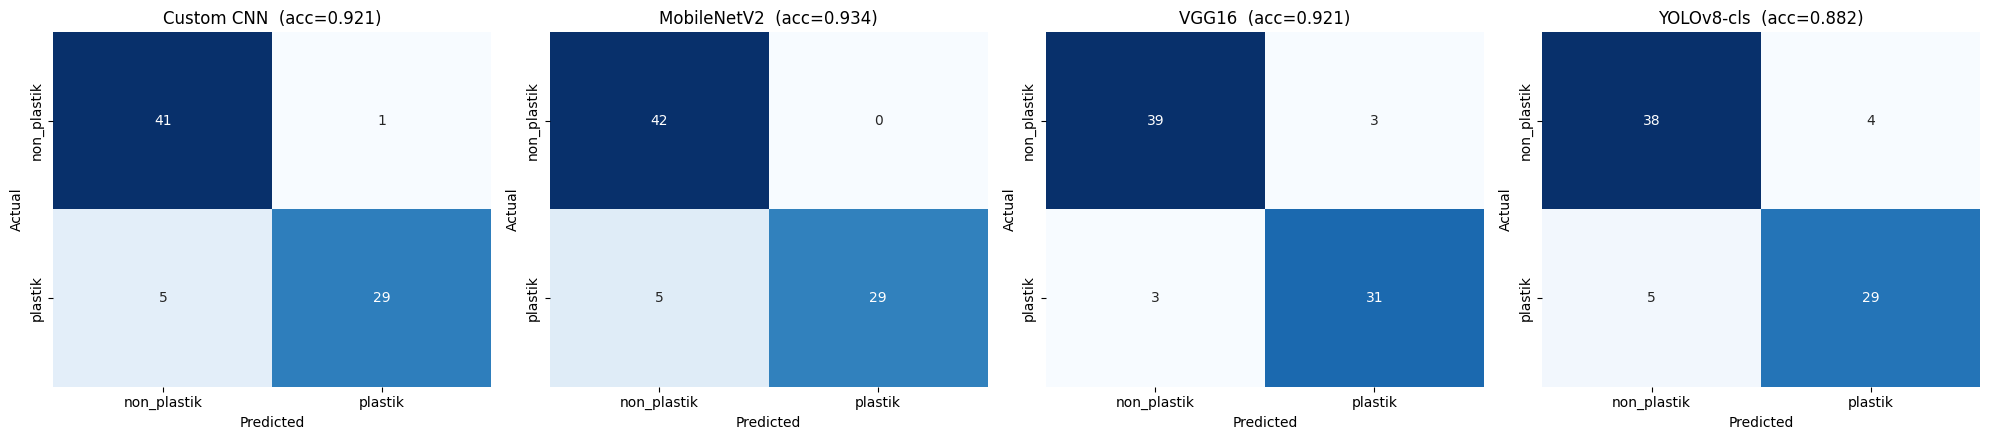

Custom CNN: TN=41, FP=1, FN=5, TP=29
MobileNetV2: TN=42, FP=0, FN=5, TP=29
VGG16: TN=39, FP=3, FN=3, TP=31
YOLOv8-cls: TN=38, FP=4, FN=5, TP=29


In [16]:
# ==========================================
# SEED UTAMA: tabel perbandingan + confusion matrix 4 model (test terisolasi)
# ==========================================
prim_res = results["clean"][PRIMARY_SEED]
prim = prim_res["preds"]
y_true_prim = prim["y_true"].to_numpy()
assert len(prim) == len(df_test), "Prediksi seed utama tidak selengkap test set"

comparison_rows, cm_dict = [], {}
for m in MODEL_ORDER:
    yp = prim[MODEL_COLS[m]].to_numpy()
    d = metrics_from_preds(y_true_prim, yp)
    cm = confusion_matrix(y_true_prim, yp, labels=[0, 1])
    cm_dict[m] = cm
    tn, fp, fn, tp = cm.ravel()
    comparison_rows.append({
        "Model": m, "Accuracy": d["accuracy"], "Precision (Macro)": d["precision_macro"],
        "Recall (Macro)": d["recall_macro"], "F1-Score (Macro)": d["f1_macro"], "Cohen's Kappa": d["kappa"],
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })
comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(os.path.join(CONFIG["save_dir"], f"comparison_primary_seed{PRIMARY_SEED}.csv"), index=False)
print(f"=== Tabel perbandingan -- seed utama {PRIMARY_SEED}, test terisolasi n={len(prim)} "
      f"(baris/kolom 0={CONFIG['class_names'][0]}, 1={CONFIG['class_names'][1]}) ===")
display(comparison_df.round(4))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (m, cm) in zip(axes, cm_dict.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CONFIG["class_names"], yticklabels=CONFIG["class_names"], ax=ax)
    acc = np.trace(cm) / cm.sum()
    ax.set_title(f"{m}  (acc={acc:.3f})")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
cm_fig_path = os.path.join(CONFIG["save_dir"], "confusion_matrices_4_models.png")
plt.savefig(cm_fig_path, dpi=300, bbox_inches="tight")
logger.info(f"Confusion matrix 4 model (seed utama {PRIMARY_SEED}) disimpan ke: {cm_fig_path}")
plt.show()

for m, cm in cm_dict.items():
    tn, fp, fn, tp = cm.ravel()
    print(f"{m}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

### 8c. Kurva training 4 model (seed utama)

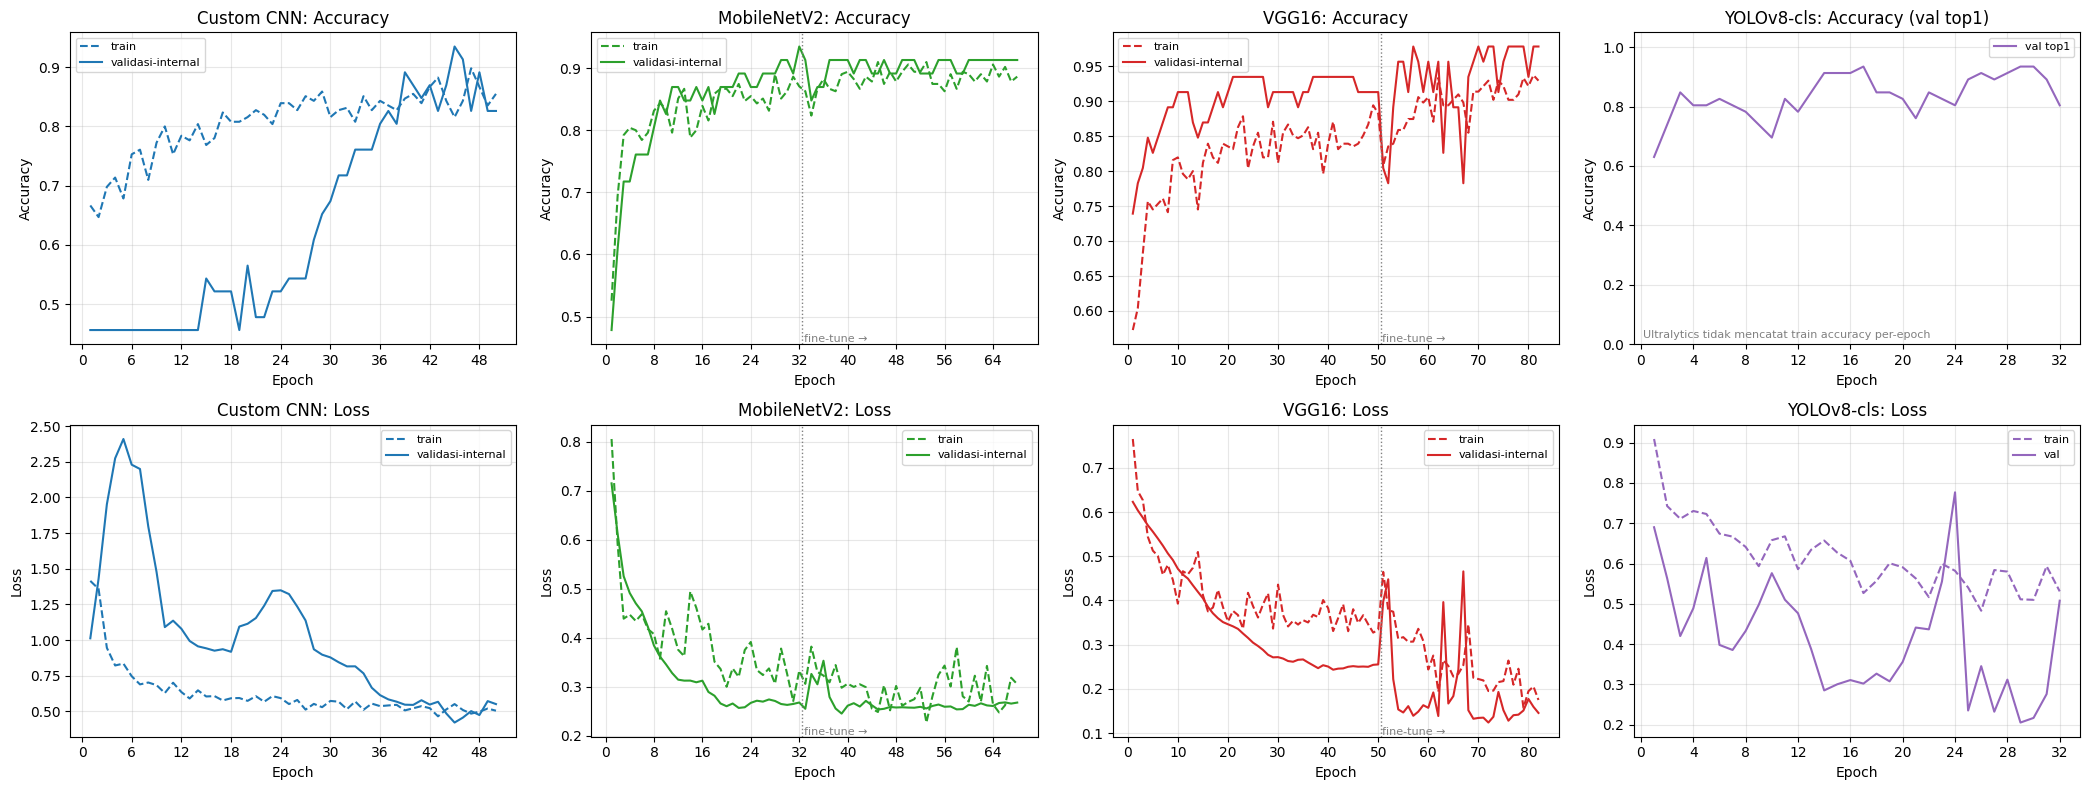

[12:27:05] INFO: Kurva training 4 model (seed utama 42) disimpan ke: /content/drive/MyDrive/project_BIMA26/model_comparison_outputs_isolated_v71/training_curves_4_models_seed42.png


In [17]:
# ==========================================
# KURVA TRAINING 4 MODEL (seed utama) -- satu figur
# Keras: train vs validasi-internal. YOLO: Ultralytics hanya mencatat accuracy pada val (top1).
# ==========================================
from matplotlib.ticker import MaxNLocator


def plot_all_training_curves(res, save_path):
    hist = res["histories"]
    fig, axes = plt.subplots(2, 4, figsize=(21, 8))
    palette = {"Custom CNN": "tab:blue", "MobileNetV2": "tab:green", "VGG16": "tab:red", "YOLOv8-cls": "tab:purple"}

    for j, m in enumerate(["Custom CNN", "MobileNetV2", "VGG16"]):
        h = hist[m]
        ep = np.arange(1, len(h["accuracy"]) + 1)
        for row, (tr, va, ylab) in enumerate([("accuracy", "val_accuracy", "Accuracy"), ("loss", "val_loss", "Loss")]):
            ax = axes[row, j]
            ax.plot(ep, h[tr], "--", color=palette[m], label="train")
            ax.plot(ep, h[va], "-", color=palette[m], label="validasi-internal")
            if h.get("phase_boundary"):
                ax.axvline(h["phase_boundary"] + 0.5, color="gray", ls=":", lw=1)
                ax.text(h["phase_boundary"] + 0.8, ax.get_ylim()[0], "fine-tune →", fontsize=8, color="gray", va="bottom")
            ax.set_title(f"{m}: {ylab}")
            ax.set_xlabel("Epoch")
            ax.set_ylabel(ylab)
            ax.grid(alpha=0.3)
            ax.legend(fontsize=8)

    ax_acc, ax_loss = axes[0, 3], axes[1, 3]
    csv_path = res.get("yolo_results_csv")
    if csv_path and os.path.exists(csv_path):
        ydf = pd.read_csv(csv_path)
        ydf.columns = [c.strip() for c in ydf.columns]
        pick = lambda cands: next((c for c in cands if c in ydf.columns), None)
        c_ep, c_trl, c_vall, c_top1 = (pick(["epoch"]), pick(["train/loss"]), pick(["val/loss"]),
                                       pick(["metrics/accuracy_top1"]))
        if c_ep and c_top1:
            ax_acc.plot(ydf[c_ep], ydf[c_top1], "-", color=palette["YOLOv8-cls"], label="val top1")
            ax_acc.set_ylim(0, 1.05)
        if c_ep and c_trl:
            ax_loss.plot(ydf[c_ep], ydf[c_trl], "--", color=palette["YOLOv8-cls"], label="train")
        if c_ep and c_vall:
            ax_loss.plot(ydf[c_ep], ydf[c_vall], "-", color=palette["YOLOv8-cls"], label="val")
        ax_acc.text(0.02, 0.02, "Ultralytics tidak mencatat train accuracy per-epoch", transform=ax_acc.transAxes,
                    fontsize=8, color="gray")
    else:
        ax_acc.text(0.5, 0.5, "results.csv YOLO tidak tersedia", ha="center", transform=ax_acc.transAxes)
    for ax, t, yl in ((ax_acc, "YOLOv8-cls: Accuracy (val top1)", "Accuracy"), (ax_loss, "YOLOv8-cls: Loss", "Loss")):
        ax.set_title(t)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if ax.get_legend_handles_labels()[0]:
            ax.legend(fontsize=8)

    for ax in axes.ravel():
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()


curves_path = os.path.join(CONFIG["save_dir"], f"training_curves_4_models_seed{PRIMARY_SEED}.png")
plot_all_training_curves(prim_res, curves_path)
logger.info(f"Kurva training 4 model (seed utama {PRIMARY_SEED}) disimpan ke: {curves_path}")

## 9. Bootstrap 95% CI dan McNemar (seed utama, ditetapkan di muka)

Seed utama = seed pertama di `train_seeds`, ditetapkan sebelum melihat hasil agar tidak ada pemilihan seed terbaik. Variasi antar seed dilaporkan terpisah di 8a.

In [18]:
# ==========================================
# BOOTSTRAP 95% CI (seed utama, test terisolasi) -- percentile, resample dengan penggantian
# ==========================================
def bootstrap_ci(df_pred: pd.DataFrame, model_cols: dict, n_boot: int, seed: int, logger: logging.Logger):
    rng = np.random.default_rng(seed)
    y = df_pred["y_true"].to_numpy()
    n = len(y)
    preds = {m: df_pred[c].to_numpy() for m, c in model_cols.items()}
    store = {m: {"accuracy": [], "f1_macro": [], "kappa": []} for m in model_cols}
    skipped = 0
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        yt = y[idx]
        if len(np.unique(yt)) < 2:       # resample satu-kelas: f1-macro/kappa tidak terdefinisi
            skipped += 1
            continue
        for m in model_cols:
            yp = preds[m][idx]
            store[m]["accuracy"].append(accuracy_score(yt, yp))
            store[m]["f1_macro"].append(f1_score(yt, yp, average="macro", labels=[0, 1], zero_division=0))
            store[m]["kappa"].append(cohen_kappa_score(yt, yp))
    if skipped:
        logger.warning(f"{skipped}/{n_boot} resample dilewati (hanya berisi 1 kelas).")
    rows = []
    for m, mets in store.items():
        row = {"Model": m}
        for k, v in mets.items():
            v = np.asarray(v)
            row[f"{k}_mean"], row[f"{k}_ci_low"], row[f"{k}_ci_high"] = v.mean(), np.percentile(v, 2.5), np.percentile(v, 97.5)
        rows.append(row)
    out = pd.DataFrame(rows)
    out["Model"] = pd.Categorical(out["Model"], categories=MODEL_ORDER, ordered=True)
    return out.sort_values("Model").reset_index(drop=True)


df_bootstrap_summary = bootstrap_ci(prim, MODEL_COLS, CONFIG["n_bootstrap"], CONFIG["bootstrap_seed"], logger)
bootstrap_save_path = os.path.join(CONFIG["save_dir"], f"bootstrap_ci_summary_seed{PRIMARY_SEED}.csv")
df_bootstrap_summary.to_csv(bootstrap_save_path, index=False)
logger.info(f"Bootstrap {CONFIG['n_bootstrap']}x (seed utama {PRIMARY_SEED}, n_test={len(prim)}) disimpan ke: {bootstrap_save_path}")
display(df_bootstrap_summary.round(4))

[12:27:28] INFO: Bootstrap 2000x (seed utama 42, n_test=76) disimpan ke: /content/drive/MyDrive/project_BIMA26/model_comparison_outputs_isolated_v71/bootstrap_ci_summary_seed42.csv


,Model,accuracy_mean,accuracy_ci_low,accuracy_ci_high,f1_macro_mean,f1_macro_ci_low,f1_macro_ci_high,kappa_mean,kappa_ci_low,kappa_ci_high
0,Custom CNN,0.9209,0.8553,0.9737,0.9177,0.8522,0.9735,0.8363,0.7085,0.9471
1,MobileNetV2,0.9340,0.8684,0.9868,0.9310,0.8661,0.9858,0.8630,0.7368,0.9715
2,VGG16,0.9211,0.8553,0.9737,0.9191,0.8510,0.9736,0.8385,0.7029,0.9473
3,YOLOv8-cls,0.8806,0.8026,0.9474,0.8773,0.7998,0.9472,0.7551,0.6016,0.8944


In [19]:
# ==========================================
# McNEMAR (seed utama): 6 pasangan model, p mentah + koreksi Holm
# ==========================================
try:
    from statsmodels.stats.contingency_tables import mcnemar
    from statsmodels.stats.multitest import multipletests
except ImportError:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "statsmodels"], check=True)
    from statsmodels.stats.contingency_tables import mcnemar
    from statsmodels.stats.multitest import multipletests


def mcnemar_test_pair(y_true, pred_a, pred_b):
    """McNemar untuk satu pasang model pada sampel yang SAMA. Eksak (binomial) bila jumlah
    pasangan diskordan < 25, selain itu chi-square dengan koreksi kontinuitas."""
    ca, cb = (pred_a == y_true), (pred_b == y_true)
    both_ok = int(np.sum(ca & cb))
    only_a = int(np.sum(ca & ~cb))
    only_b = int(np.sum(~ca & cb))
    both_bad = int(np.sum(~ca & ~cb))
    if only_a + only_b == 0:                      # tidak ada perbedaan sama sekali
        return 0.0, 1.0, only_a, only_b, both_ok, both_bad, "n/a (tidak ada pasangan diskordan)"
    use_exact = (only_a + only_b) < 25
    res = mcnemar([[both_ok, only_a], [only_b, both_bad]], exact=use_exact, correction=not use_exact)
    return float(res.statistic), float(res.pvalue), only_a, only_b, both_ok, both_bad, "eksak" if use_exact else "chi-square"


rows = []
for a, b in combinations(MODEL_ORDER, 2):
    stat, p, only_a, only_b, both_ok, both_bad, kind = mcnemar_test_pair(
        y_true_prim, prim[MODEL_COLS[a]].to_numpy(), prim[MODEL_COLS[b]].to_numpy())
    rows.append({"Model A": a, "Model B": b, "Hanya A benar": only_a, "Hanya B benar": only_b,
                 "Keduanya benar": both_ok, "Keduanya salah": both_bad,
                 "Uji": kind, "Statistik": round(stat, 4), "p (mentah)": p})
df_mcnemar = pd.DataFrame(rows)
df_mcnemar["p (Holm)"] = multipletests(df_mcnemar["p (mentah)"].to_numpy(), method="holm")[1]
df_mcnemar["Signifikan (Holm<0.05)"] = np.where(df_mcnemar["p (Holm)"] < 0.05, "Ya", "Tidak")
df_mcnemar[["p (mentah)", "p (Holm)"]] = df_mcnemar[["p (mentah)", "p (Holm)"]].round(4)

mcnemar_save_path = os.path.join(CONFIG["save_dir"], f"mcnemar_results_seed{PRIMARY_SEED}.csv")
df_mcnemar.to_csv(mcnemar_save_path, index=False)
logger.info(f"McNemar (seed utama {PRIMARY_SEED}) disimpan ke: {mcnemar_save_path}")
display(df_mcnemar)

[12:27:29] INFO: McNemar (seed utama 42) disimpan ke: /content/drive/MyDrive/project_BIMA26/model_comparison_outputs_isolated_v71/mcnemar_results_seed42.csv


,Model A,Model B,Hanya A benar,Hanya B benar,Keduanya benar,Keduanya salah,Uji,Statistik,p (mentah),p (Holm),Signifikan (Holm<0.05)
0,Custom CNN,MobileNetV2,1,2,69,4,eksak,1.0,1.0000,1.0,Tidak
1,Custom CNN,VGG16,3,3,67,3,eksak,3.0,1.0000,1.0,Tidak
2,Custom CNN,YOLOv8-cls,6,3,64,3,eksak,3.0,0.5078,1.0,Tidak
3,MobileNetV2,VGG16,3,2,68,3,eksak,2.0,1.0000,1.0,Tidak
4,MobileNetV2,YOLOv8-cls,5,1,66,4,eksak,1.0,0.2188,1.0,Tidak
5,VGG16,YOLOv8-cls,6,3,64,3,eksak,3.0,0.5078,1.0,Tidak


## 10. Analisis kesalahan dan stabilitas

=== Distribusi kesalahan (n_test=76; model dihitung: ['Custom CNN', 'MobileNetV2', 'VGG16', 'YOLOv8-cls']) ===


,jumlah_patch
salah_oleh_n_model,
0,62
1,8
2,2
3,2
4,2


[12:27:29] INFO: 6 patch salah pada >=2 model (kandidat label noise / piksel campuran) -> /content/drive/MyDrive/project_BIMA26/model_comparison_outputs_isolated_v71/hard_examples_seed42.csv
Patch yang salah pada SEMUA 4 model yang dihitung: ['tile_00003.png', 'tile_00009.png']
Periksa patch-patch ini secara visual/di GIS: bila banyak yang ternyata berlabel ragu, itu temuan yang layak ditulis di bagian pembahasan.


,filename,Custom CNN,MobileNetV2,VGG16,YOLOv8-cls,label_benar,n_model_salah
0,tile_00003.png,True,True,True,True,plastik,4
2,tile_00009.png,True,True,True,True,plastik,4
21,tile_00137.png,True,True,True,False,plastik,3
48,tile_00574.png,True,True,False,True,plastik,3
20,tile_00128.png,False,False,True,True,non_plastik,2
60,tile_00757.png,False,True,False,True,plastik,2


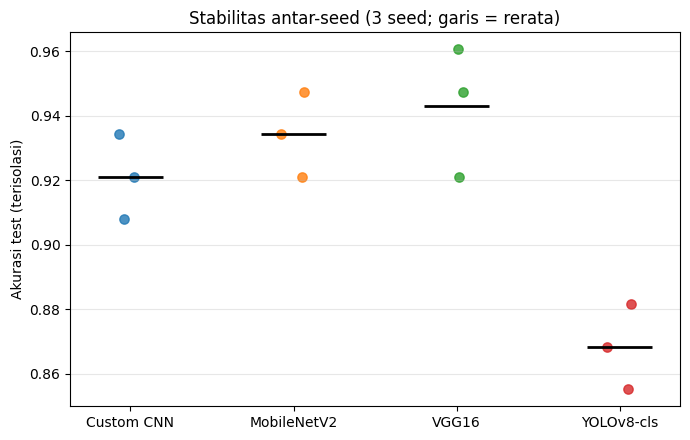

In [20]:
# ==========================================
# ANALISIS KESALAHAN (seed utama): patch mana yang salah, dan oleh berapa model
# ==========================================
wrong = pd.DataFrame({m: (prim[MODEL_COLS[m]].to_numpy() != y_true_prim) for m in MODEL_ORDER})
wrong.insert(0, "filename", prim["filename"].to_numpy())
wrong["label_benar"] = [CONFIG["class_names"][i] for i in y_true_prim]
_flags = (prim_res.get("meta") or {}).get("collapsed_on_val") or {}
EXCLUDED = [m for m in MODEL_ORDER if _flags.get(m)]
INCLUDED = [m for m in MODEL_ORDER if m not in EXCLUDED] or list(MODEL_ORDER)
if EXCLUDED and len(EXCLUDED) == len(MODEL_ORDER):
    print("Catatan: SEMUA model terdegenerasi pada validasi-internal -- analisis memakai semua model (tidak bermakna).")
elif EXCLUDED:
    print(f"Catatan: {EXCLUDED} memprediksi SATU kelas saja pada validasi-internal (terdegenerasi) -> dikeluarkan dari "
          f"analisis tumpang-tindih kesalahan, supaya kesalahan model rusak tidak tampak sebagai 'patch sulit'.")
wrong["n_model_salah"] = wrong[INCLUDED].sum(axis=1)

overlap = (wrong["n_model_salah"].value_counts().reindex(range(len(INCLUDED) + 1), fill_value=0)
           .rename("jumlah_patch").to_frame())
overlap.index.name = "salah_oleh_n_model"
print(f"=== Distribusi kesalahan (n_test={len(prim)}; model dihitung: {INCLUDED}) ===")
display(overlap)

hard = wrong[wrong["n_model_salah"] >= min(2, len(INCLUDED))].sort_values("n_model_salah", ascending=False)
hard_path = os.path.join(CONFIG["save_dir"], f"hard_examples_seed{PRIMARY_SEED}.csv")
hard.to_csv(hard_path, index=False)
logger.info(f"{len(hard)} patch salah pada >={min(2, len(INCLUDED))} model (kandidat label noise / piksel campuran) -> {hard_path}")
print(f"Patch yang salah pada SEMUA {len(INCLUDED)} model yang dihitung:",
      wrong.loc[wrong['n_model_salah'] == len(INCLUDED), 'filename'].tolist())
print("Periksa patch-patch ini secara visual/di GIS: bila banyak yang ternyata berlabel ragu, "
      "itu temuan yang layak ditulis di bagian pembahasan.")
display(hard.head(15))

# --- Stabilitas antar-seed (titik = satu seed) ---
fig, ax = plt.subplots(figsize=(7, 4.5))
rng_plot = np.random.default_rng(0)
for i, m in enumerate(MODEL_ORDER):
    accs = df_seed_metrics.loc[df_seed_metrics["model"] == m, "accuracy"].to_numpy()
    ax.scatter(i + rng_plot.uniform(-0.08, 0.08, size=len(accs)), accs, s=45, alpha=0.8)
    ax.hlines(accs.mean(), i - 0.2, i + 0.2, color="black", lw=2)
ax.set_xticks(range(len(MODEL_ORDER)))
ax.set_xticklabels(MODEL_ORDER)
ax.set_ylabel("Akurasi test (terisolasi)")
ax.set_title(f"Stabilitas antar-seed ({len(CONFIG['train_seeds'])} seed; garis = rerata)")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
stab_path = os.path.join(CONFIG["save_dir"], "seed_stability_accuracy.png")
plt.savefig(stab_path, dpi=300, bbox_inches="tight")
plt.show()

## 11. (Opsional) Dampak protokol lama: test sebagai monitor EarlyStopping

In [21]:
# ==========================================
# (OPSIONAL) DAMPAK PROTOKOL LAMA: test dipakai sebagai monitor EarlyStopping
# Hanya berjalan bila CONFIG["run_leaky_arm"] = True. Train set IDENTIK dengan lengan bersih,
# sehingga selisih akurasi test mengisolasi efek "memantau test saat training".
# ==========================================
if CONFIG["run_leaky_arm"] and results["leaky"]:
    df_leaky_metrics = build_seed_metrics(results["leaky"], "leaky")
    both = pd.concat([df_seed_metrics, df_leaky_metrics], ignore_index=True)
    both.to_csv(os.path.join(CONFIG["save_dir"], "metrics_per_seed_both_arms.csv"), index=False)

    rows = []
    for m in MODEL_ORDER:
        c = df_seed_metrics[df_seed_metrics["model"] == m].set_index("seed")["accuracy"]
        l = df_leaky_metrics[df_leaky_metrics["model"] == m].set_index("seed")["accuracy"]
        diff = (l - c).dropna()
        rows.append({
            "Model": m,
            "Akurasi lengan bersih (mean)": round(c.mean(), 4),
            "Akurasi lengan 'test-dimonitor' (mean)": round(l.mean(), 4),
            "Selisih (leaky - bersih)": round(diff.mean(), 4),
            "Selisih per seed": ", ".join(f"{v:+.3f}" for v in diff.to_numpy()),
        })
    df_leak_delta = pd.DataFrame(rows)
    print("=== Efek memantau test saat training (train set sama; n_test = %d) ===" % len(df_test))
    display(df_leak_delta)
    df_leak_delta.to_csv(os.path.join(CONFIG["save_dir"], "leakage_effect_by_model.csv"), index=False)
    print("Catatan: selisih positif = optimisme akibat seleksi pada test. Dengan test sekecil ini selisih "
          "bisa dalam kisaran derau; laporkan sebagai analisis sensitivitas, bukan klaim umum.")
else:
    logger.info("Lengan 'protokol lama' tidak dijalankan (CONFIG['run_leaky_arm']=False) -- sel ini dilewati.")

[12:27:30] INFO: Lengan 'protokol lama' tidak dijalankan (CONFIG['run_leaky_arm']=False) -- sel ini dilewati.


## 12. Ringkasan siap-tempel, audit, dan manifest

In [23]:
# ==========================================
# RINGKASAN + AUDIT + MANIFEST
# ==========================================
lines = []
lines.append(f"PARTISI (split_seed={CONFIG['split_seed']}, hash {SPLIT_HASH[:12]}): total {len(df_clean)} patch bersih "
              f"({len(df)} awal, {len(df_removed)} dibuang) -> train {len(df_base_train)} / val-internal {len(df_val)} / "
              f"test terisolasi {len(df_test)}  "
              f"({len(df_base_train)/len(df_clean):.1%} / {len(df_val)/len(df_clean):.1%} / {len(df_test)/len(df_clean):.1%})")
lines.append(f"Penyeimbangan kelas: {CONFIG['balance_mode']} | seed training: {CONFIG['train_seeds']} (utama = {PRIMARY_SEED})")
lines.append(f"Protokol {CODE_VERSION}: es_start_from_epoch={CONFIG['es_start_from_epoch']} (0 = v7 asli) | "
             f"lr fine-tune VGG16={CONFIG['vgg_finetune_lr']} (v7 asli 1e-4) | lr fine-tune MobileNetV2={CONFIG['mobilenet_finetune_lr']}")
lines.append("")
lines.append(f"=== Hasil lintas seed (mean ± SD; n_test={len(df_test)}) ===")
for _, r in df_seed_summary.iterrows():
    lines.append(f"{r['Model']:<12} Acc {r['Accuracy (mean ± SD)']} | F1 {r['Macro-F1 (mean ± SD)']} | "
                 f"Kappa {r['Kappa (mean ± SD)']} | rentang Acc {r['Acc min–max']}")
lines.append("")
lines.append(f"=== Bootstrap 95% CI ({CONFIG['n_bootstrap']} resample, seed utama {PRIMARY_SEED}) ===")
for _, r in df_bootstrap_summary.iterrows():
    lines.append(f"{r['Model']}: Acc {r['accuracy_mean']:.4f} [{r['accuracy_ci_low']:.4f}–{r['accuracy_ci_high']:.4f}] | "
                 f"F1 {r['f1_macro_mean']:.4f} [{r['f1_macro_ci_low']:.4f}–{r['f1_macro_ci_high']:.4f}] | "
                 f"Kappa {r['kappa_mean']:.4f} [{r['kappa_ci_low']:.4f}–{r['kappa_ci_high']:.4f}]")
lines.append("")
lines.append(f"=== McNemar (seed utama {PRIMARY_SEED}; p mentah / Holm) ===")
for _, r in df_mcnemar.iterrows():
    verdict = "SIGNIFIKAN" if r["Signifikan (Holm<0.05)"] == "Ya" else "tidak signifikan"
    lines.append(f"{r['Model A']} vs {r['Model B']}: hanya-A={r['Hanya A benar']}, hanya-B={r['Hanya B benar']}, "
                 f"p={r['p (mentah)']:.4f} / {r['p (Holm)']:.4f} -> {verdict} ({r['Uji']})")
lines.append("")
lines.append("=== Diagnostik degenerasi (model memprediksi SATU kelas saja pada validasi-internal) ===")
for _s, _r in results["clean"].items():
    _fl = _r["meta"].get("collapsed_on_val")
    _bad = [m for m, v in (_fl or {}).items() if v]
    lines.append(f"seed {_s}: " + ("n/a" if _fl is None else (", ".join(_bad) if _bad else "tidak ada")))
lines.append("")
lines.append("=== Akurasi TRAIN tanpa augmentasi (mode inferensi) vs VALIDASI-internal ===")
lines.append("(train tinggi & validasi rendah = celah generalisasi; keduanya rendah = masalah mode-inferensi / BatchNorm / augmentasi)")
for _s, _r in results["clean"].items():
    _tr = _r["meta"].get("train_acc_inference") or {}
    _va = _r["meta"].get("val_acc_internal") or {}
    lines.append(f"seed {_s}: " + " | ".join(f"{m} train {_tr[m]:.3f} / val {_va.get(m, float('nan')):.3f}" for m in _tr))
lines.append("")
lines.append("=== Pernyataan metode (draf Inggris, angka terisi otomatis; periksa sebelum dipakai) ===")
lines.append(
    f"After removing exact duplicates, {len(df_clean)} patches were split in a stratified manner (seed {CONFIG['split_seed']}) "
    f"into training (n={len(df_base_train)}), internal validation (n={len(df_val)}) and an isolated test set (n={len(df_test)}). "
    f"The test set was excluded before any training and was used only to generate the final predictions; early stopping, "
    f"learning-rate scheduling and checkpoint selection monitored the internal validation set only; "
    f"early stopping ignored the first {CONFIG['es_start_from_epoch']} epochs so that no checkpoint could be selected from the warm-up phase. "
    f"Each architecture was trained with {len(CONFIG['train_seeds'])} random seeds on the same partition; "
    f"bootstrap confidence intervals and McNemar tests (Holm-adjusted) are reported for the pre-specified primary seed ({PRIMARY_SEED}).")
summary_text = "\n".join(lines)
print(summary_text)
with open(os.path.join(CONFIG["save_dir"], "ringkasan_siap_tempel.txt"), "w", encoding="utf-8") as f:
    f.write(summary_text)

# --- Audit akhir ---
audit = {
    "partisi_saling_lepas": True,   # sudah di-assert di sel Split
    "test_n": int(len(df_test)),
    "test_dipakai_untuk_monitor_training_lengan_bersih": False,
    "dataset_yolo_test_sesuai_df_test": True,   # diverifikasi di prepare_yolo_folder_structure
    "seed_utama_ditetapkan_di_muka": PRIMARY_SEED,
    "fine_tuning_aktif_diverifikasi": True,     # train_two_phase berhenti dengan error bila tidak aktif
}
manifest = {
    "code_version": CODE_VERSION, "finished_at": pd.Timestamp.now().isoformat(),
    "environment": {"python": platform.python_version(), "tensorflow": tf.__version__,
                    "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__,
                    "gpu": [d.name for d in gpu_devices]},
    "config": {k: v for k, v in CONFIG.items() if not k.endswith("_dir") and k not in ("csv_path",)},
    "split_hash": SPLIT_HASH, "checks_enforced_by_code": audit,
    "protocol_amendments_vs_v7": {"es_start_from_epoch": {"v7": 0, "this_run": CONFIG["es_start_from_epoch"]},
                                  "vgg_finetune_lr": {"v7": 1e-4, "this_run": CONFIG["vgg_finetune_lr"]}},
}
manifest["environment"]["yolo_worker"] = results["clean"][PRIMARY_SEED]["meta"].get("yolo_env")
with open(os.path.join(CONFIG["save_dir"], "run_manifest.json"), "w") as f:
    json.dump(manifest, f, indent=2, default=str)
logger.info(f"Manifest run + ringkasan tersimpan di {CONFIG['save_dir']}. Selesai.")
print("\nUNTUK DIKIRIM: unduh notebook ini (.ipynb dengan output), atau tempel output sel Split, "
      "tabel lintas-seed, tabel seed utama, bootstrap, McNemar, dan sel ringkasan ini.")

PARTISI (split_seed=42, hash 5b16f7467b08): total 377 patch bersih (385 awal, 8 dibuang) -> train 255 / val-internal 46 / test terisolasi 76  (67.6% / 12.2% / 20.2%)
Penyeimbangan kelas: class_weight | seed training: [42, 1337, 2024] (utama = 42)
Protokol v7.1-isolated-3way-multiseed-esstart: es_start_from_epoch=15 (0 = v7 asli) | lr fine-tune VGG16=1e-05 (v7 asli 1e-4) | lr fine-tune MobileNetV2=1e-05

=== Hasil lintas seed (mean ± SD; n_test=76) ===
Custom CNN   Acc 0.9211 ± 0.0132 | F1 0.9185 ± 0.0140 | Kappa 0.8379 ± 0.0275 | rentang Acc 0.9079–0.9342
MobileNetV2  Acc 0.9342 ± 0.0132 | F1 0.9326 ± 0.0132 | Kappa 0.8656 ± 0.0265 | rentang Acc 0.9211–0.9474
VGG16        Acc 0.9430 ± 0.0201 | F1 0.9421 ± 0.0201 | Kappa 0.8843 ± 0.0403 | rentang Acc 0.9211–0.9605
YOLOv8-cls   Acc 0.8684 ± 0.0132 | F1 0.8661 ± 0.0139 | Kappa 0.7323 ± 0.0275 | rentang Acc 0.8553–0.8816

=== Bootstrap 95% CI (2000 resample, seed utama 42) ===
Custom CNN: Acc 0.9209 [0.8553–0.9737] | F1 0.9177 [0.8522–0.97